# Does the base model predict which coding tasks can be nudged?

**Panel A of iteration 5, Step 2.** Qwen3-8B (instruct, thinking off) and Qwen3-8B-Base, bf16, one RTX 4090.

Ask Qwen3-8B for a Python solution to a coding task and it almost always writes the **same algorithm**, its *default*. For "majority element" that is a hash-map count, never the Boyer–Moore vote. Earlier iterations found a small **isotropic push** that moves *some* tasks off their default and leaves others pinned. The push is a random direction added to the hidden states of the task-specification tokens, in decoder blocks 12–23, during prompt prefill only. This experiment tests whether the **base model**, before any push, forecasts **which tasks move and where they land**:

* **Claim A1 (whether a task moves).** The base model's correct-only off-default share **β_u** predicts the escape fraction **E_u**. β_u is sampled on the instruct twin's exact chat-templated token ids. E_u is measured over a fixed population of push directions: 8 isotropic directions × dose α ∈ {1, 2}.
* **Claim A2 (where a pushed task lands).** The base model's most frequent correct non-default algorithm **r_u** predicts the landing **L_u** of the confirmed escapes. It also beats an association prompt and an AST-proximity forecast on log score.

Every forecast was sha256-committed into a hash chain (`commitments.log`) **before** its unit's first push row was sampled.

### What this notebook runs
The artifact's entry point `method.py` dispatches four stages: `setup | workers | unit <u> | final`. The first three need two 8B models on a GPU (about 1 GPU-hour of sampling), a sandbox that runs every program against hidden tests, and LLM judges, so they are **not** re-run here. Their output, **8,030 labelled programs from 23 tasks**, is bundled in `mini_demo_data.json`. This notebook re-runs the CPU part of the `final` stage on those rows, with the original code copied cell by cell:

| `final` step of `method.py` | in this notebook |
|---|---|
| `src/final_run.py`: the frozen `analysis_a1a2.py` + `escape_rule.py` + `metrics.py` (A1, A2, Extra arm A, 'half + screen') | **run** |
| `src/assoc_fix.py`: POST HOC corrected association rival | **run** |
| `src/verify_chain.py`: hash chain of the commitments | **run** |
| `fix_validity`, `novelty_audit`, `engine_check`, `recheck`, `external_refs` | not run: they need the sandbox, the judges or the FP8 screen rows. Their outcomes are quoted at the end |
| `outputs5`, `figures5`, `report5`, `audit/rederive.py` | replaced by the summary tables and figures at the end |

**Reported result.** A1 is *not* supported: on the primary set (n = 6), Spearman ρ(β, E) = −0.03 with exact one-sided p = 0.56. A2 *is* supported: the base runner-up equals the push landing on 3 of 3 movable units (Poisson-binomial p = 0.019).

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT pre-installed on Colab, always install (the original scripts log with it)
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, pandas -- pre-installed on Colab, install locally only (at Colab's exact versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0', 'pandas==2.2.2')

In [2]:
from __future__ import annotations

# --- method.py (the original import block) ---
import subprocess
import sys
from pathlib import Path

# --- src/cfg5.py, metrics.py, escape_rule.py, analysis_a1a2.py, final_run.py, assoc_fix.py, commit5.py ---
import hashlib
import itertools
import json
import math
import re
import shutil
from collections import Counter
from datetime import datetime, timezone
from typing import Any, Sequence

import numpy as np
from loguru import logger
from scipy import stats

# --- notebook additions: timing, summary tables and figures ---
import time

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_0oWBKrKEGsmU/round-5/experiment-25/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
print(f'loaded {data["metadata"]["n_examples"]} tasks with {data["metadata"]["n_label_rows"]} labelled programs')

GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
loaded 23 tasks with 8030 labelled programs


## What the bundled data holds

`mini_demo_data.json` holds one **example per task**, 23 in all:

* **8 new units** built for this panel from LeetCode problems. The pre-registered primary set is A1 majority element, A2 maximum block sum, A3 trapped rain water, A4 count primes, A5 longest common prefix and A7 longest mirrored substring. The reserve extension is A8 jump game and A9 median of two sorted lists. A6 (number of islands) failed its labeller gate and has no rows.
* **15 existing tasks** from earlier iterations, such as T03 k-th smallest, T10 connected components and T1/T2 shortest paths. *Extra arm A* re-measured them with the same push protocol.

Each example lists its **label rows**, one per sampled program. A row records the arm, the model and the CRN slot, plus the push direction and dose for escape rows. It also gives the program's algorithm label and whether the program passed the hidden tests. The runtime and AST labellers assign the label, and LLM judges decide when the two disagree. The arms of a new unit are:

| arm | model | N | what it is |
|---|---|---|---|
| `TWIN` | instruct | 50 | neutral twin prompt (5 templates × 10 CRN slots); defines the **default** |
| `BASE` | base | 100 | the same chat-templated token ids fed to Qwen3-8B-Base; gives **β_u** and **r_u** |
| `PLAINC` | base | 50 | plain-completion prompt (sensitivity) |
| `NOVELTY` | instruct | 30 | "Write a novel algorithm for this task…" (a rival) |
| `ESC_d<seed>_a<α>` | instruct | 10 or 30 per cell | **push rows**: 8 fixed isotropic directions × α ∈ {1, 2}. Every cell gets 10 rows; cells that pass the screen get 20 more |
| `PN_a1.0`, `PN_a2.0` | instruct | 50 each | plan noise: a fresh random direction for every row |
| `T1.3` | instruct | 50 | temperature 1.3 (a knob row) |

New units also carry three more things:

* the exact text of their committed prediction file (`predictions/unit_<u>.json`);
* the unit spec: the catalogue of algorithm *modes* and their aliases;
* the 20 answers to the association prompt.

The next cell prints the row counts per task and what unit A1 looks like.

In [5]:
for ex in data["examples"]:
    arms = Counter("ESC_*" if r["arm"].startswith("ESC_") else r["arm"] for r in ex["rows"])
    print(f'{ex["task"]:>4}  {ex["kind"]:<17} {ex["name"]:<34} {len(ex["rows"]):>4} rows: ' +
          ", ".join(f"{a} {n}" for a, n in arms.items()))

a1 = next(ex for ex in data["examples"] if ex["task"] == "A1")
print("\nA1:", a1["description"])
print("catalogue:", [(c["mode"], c["display_name"]) for c in a1["spec"]["catalogue"]])
print("\none twin row:  ", a1["rows"][0])
print("one escape row:", next(r for r in a1["rows"] if r["arm"].startswith("ESC_")))
# three correct A1 programs: the instruct twin's default, the base model's runner-up and a confirmed push landing
for kind, prog in a1["example_programs"].items():
    print(f"\n--- {kind} = {prog['label']} ({prog['sample_id']}) ---\n{prog['code']}")

  A1  new_unit_primary  A1_majority_element                 620 rows: TWIN 50, NOVELTY 30, BASE 100, PLAINC 50, ESC_* 240, PN_a1.0 50, PN_a2.0 50, T1.3 50
  A2  new_unit_primary  A2_max_subarray                     540 rows: TWIN 50, NOVELTY 30, BASE 100, PLAINC 50, ESC_* 160, PN_a1.0 50, PN_a2.0 50, T1.3 50
  A3  new_unit_primary  A3_trapping_rain_water              680 rows: TWIN 50, NOVELTY 30, BASE 100, PLAINC 50, ESC_* 300, PN_a1.0 50, PN_a2.0 50, T1.3 50
  A4  new_unit_primary  A4_count_primes                     540 rows: TWIN 50, NOVELTY 30, BASE 100, PLAINC 50, ESC_* 160, PN_a1.0 50, PN_a2.0 50, T1.3 50
  A5  new_unit_primary  A5_longest_common_prefix            540 rows: TWIN 50, NOVELTY 30, BASE 100, PLAINC 50, ESC_* 160, PN_a1.0 50, PN_a2.0 50, T1.3 50
  A7  new_unit_primary  A7_longest_palindromic_substring    600 rows: TWIN 50, NOVELTY 30, BASE 100, PLAINC 50, ESC_* 220, PN_a1.0 50, PN_a2.0 50, T1.3 50
  A8  new_unit_reserve  A8_jump_game                        540 rows: 

## Configuration

The analysis is deterministic given its seeds. The knobs below only set how many resamples three statistics use:

* the **bootstrap intervals**;
* the **random-permutation p-value**, which is used only when more than 9 units are correlated ('half + screen');
* the **rarefied Hill-1 diversity**.

The point estimates (β, E, ρ, the hits, the log scores, the exact p-values for n ≤ 9) do not depend on them. The cell ships with the **original** counts. With them the whole notebook runs in about a minute and reproduces every reported number exactly. Smaller values give a quicker smoke run; a suggested set is in the comment.

In [6]:
# Tunable parameters: resample / permutation / subsample counts of the frozen analysis and of the figures.
# These are the ORIGINAL values (the whole notebook runs in about a minute with them); for a quicker smoke run use
# e.g. N_BOOT = 200, N_BOOT_RIVAL = 1000, HILL_N_SUB = 100, N_PERM_RANDOM = 1000, E_BOOT = 50.
# (Re-run the cells below after changing them: the metrics cell binds HILL_N_SUB and N_PERM_RANDOM as defaults.)
N_BOOT = 2000           # measurement bootstrap of rho(beta, E)                   (cfg5.N_BOOT)
N_BOOT_RIVAL = 10000    # task bootstrap of each rival's Delta (CI needs >= 100)  (cfg5.N_BOOT_RIVAL)
HILL_N_SUB = 1000       # subsamples of the rarefied Hill-1 diversity             (metrics.hill1_rarefied default)
N_PERM_RANDOM = 10000   # random permutations of the Spearman p when n > 9        (metrics.perm_p_spearman default)
E_BOOT = 500            # per-unit row bootstrap behind fig. 1's E error bars      (figures5.e_boot default)

## The original entry point: `method.py`

`method.py` is a stage dispatcher. Each stage shells out to scripts in `src/` with the repository's own `.venv` Python. It is reproduced verbatim here, for reference only: `setup`, `workers` and `unit` need the full repository, a GPU with Qwen3-8B / Qwen3-8B-Base, the program sandbox and the OpenRouter judges.

```python
"""Panel A (iteration 5, Step 2): does the base model's repertoire forecast which coding tasks a ban-free isotropic
plan push can move, and where they land? Entry point that runs every stage of the pipeline in src/.

METHOD (the forecast under test): for each unit, the correct-only off-default share beta_u of Qwen3-8B-Base on the
instruct twin's exact token ids (predicted class MOVABLE iff beta_u >= 0.05) and its most frequent correct non-default
algorithm r_u (predicted landing), sha256-committed before any push.
BASELINES / RIVALS (pre-registered, computed ban-free before the commitment): the instruct model's opening margin
(teacher-forced log-prob of each mode's first body tokens), the merit gap (runtime and length ratios of each mode's
reference to the default's), the twin's modal share, the novelty-instruction off-default share, the association prompt
('What is the standard alternative to <default>?') and AST proximity (Zhang-Shasha distance of each mode's reference to
the twin's default programs). A1 compares rho(beta, E) with every rival; A2 compares the log score of the base
composition with association and proximity on the realised landings.

Usage:
  python method.py setup        # stage 0 + frozen specs/prompts + CPU tests (fresh checkout only: in this workspace
                                # it would overwrite files already committed in commitments.log)
  python method.py workers      # start gpu_worker, label_worker5 and controller in the background
  python method.py unit A1      # build, gate (round 0), freeze and commit one unit (pushes follow automatically)
  python method.py final        # every post-sampling stage: analysis, audits, outputs, figures, report, re-derivation
"""

from __future__ import annotations

import subprocess
import sys
from pathlib import Path

ROOT = Path(__file__).resolve().parent
PY = str(ROOT / ".venv" / "bin" / "python")


def run(args: list[str], check: bool = True) -> int:
    print("+", " ".join(a.replace(str(ROOT) + "/", "") for a in args), flush=True)
    r = subprocess.run(args, cwd=ROOT)
    if check and r.returncode != 0:
        raise SystemExit(f"step failed ({r.returncode}): {' '.join(args)}")
    return r.returncode


def setup() -> None:
    run([PY, "src/stage0.py"])
    run([PY, "src/specs5.py"])
    run([PY, "-m", "pytest", "-q", "-c", "pytest.ini", "tests"])


def workers() -> None:
    for script in ("src/gpu_worker.py", "src/label_worker5.py", "src/controller.py"):
        log = open(ROOT / "logs" / (Path(script).stem + ".out"), "a")
        p = subprocess.Popen([PY, script], cwd=ROOT, stdout=log, stderr=subprocess.STDOUT)
        print(f"started {script} pid {p.pid}")


def unit(u: str) -> None:
    run([PY, "-m", "newbench.common.build5", u])
    run([PY, "-m", "newbench.common.gate5", u])
    run([PY, "src/freeze_unit.py", u, "round0"])
    run([PY, "src/unit_commit.py", u])


def final() -> None:
    steps = [[PY, "src/fix_validity.py"], [PY, "src/novelty_audit.py"], [PY, "src/final_run.py"],
             [PY, "src/assoc_fix.py"],
             [PY, "src/engine_check.py"], [PY, "src/recheck.py"], [PY, "src/external_refs.py"],
             [PY, "src/outputs5.py"], [PY, "src/figures5.py"], [PY, "src/report5.py"],
             ["python3", "-I", "audit/rederive.py"], [PY, "src/verify_chain.py"]]
    for s in steps:
        run(s)


if __name__ == "__main__":
    if len(sys.argv) < 2 or sys.argv[1] not in ("setup", "workers", "unit", "final"):
        print(__doc__)
        sys.exit(2)
    cmd = sys.argv[1]
    if cmd == "setup":
        setup()
    elif cmd == "workers":
        workers()
    elif cmd == "unit":
        unit(sys.argv[2])
    else:
        final()
```

The cells below copy the code behind `final` that runs on CPU from the labelled rows. That covers `src/cfg5.py` (excerpt), `src/metrics.py`, `src/escape_rule.py` and `src/analysis_a1a2.py`; the last three were sha256-committed at #0 and never edited afterwards. Then come `src/final_run.py`, `src/assoc_fix.py` and `src/commit5.py` / `src/verify_chain.py`. At the end, a `final()` cell runs those steps in the original order. The edits are limited to file access: each changed line is marked `# was: …`.

## Frozen constants (`src/cfg5.py`, excerpt)

The thresholds, seeds and unit lists below were committed in `predictions/protocol_commit0.json` (commit #0) **before** any push was sampled. They are the protocol, not tuning knobs. Only the paths change: the notebook reads its inputs from `data` and writes the same result JSONs as the original into `./results`. The JSON helpers are copied unchanged.

In [7]:
ROOT = Path.cwd()           # was: Path(__file__).resolve().parents[1] (the repository root)
RESULTS = ROOT / "results"  # the analysis writes its result JSONs here, as the original does
RESULTS.mkdir(parents=True, exist_ok=True)

ESC_SEEDS = [95101, 95102, 95103, 95104, 95105, 95106, 95107, 95108]
ALPHAS = (1.0, 2.0)

# thresholds (frozen at commit #0)
BETA_MOVABLE = 0.05
DEFAULT_SHARE = 0.60
ESC_EXCESS = 0.20
ESC_PASS_FRAC = 0.80
P_BINOM = 0.05
MIN_CORRECT_BASE = 20
DEPTH = 25
EXCLUDE = ("invalid", "disputed")
# N_BOOT = 2000 and N_BOOT_RIVAL = 10000 in cfg5.py -> set in the config cell above
BOOT_SEED = 20261021

# units of panel A (new) -- list order is the build order; A8/A9 are reserves under the mid-artifact rule
NEW_UNITS = ["A1", "A2", "A3", "A4", "A5", "A6", "A7"]
RESERVE_UNITS = ["A8", "A9"]
UNIT_DIRS = {"A1": "A1_majority_element", "A2": "A2_max_subarray", "A3": "A3_trapping_rain_water",
             "A4": "A4_count_primes", "A5": "A5_longest_common_prefix", "A6": "A6_number_of_islands",
             "A7": "A7_longest_palindromic_substring", "A8": "A8_jump_game", "A9": "A9_median_two_sorted"}

# existing tasks (Extra arm A): order = T03, T10 (positive controls) then the 13 others
PATH_TASKS = ("T1", "T2")
EXISTING = ["T03", "T10", "T05", "T06", "T1", "T2", "T04", "T08", "T11", "T13", "T14", "R1", "R3", "R6", "R2"]
EXISTING_DEFAULT = {"T1": "bfs", "T2": "dijkstra", "T03": "full_sort", "T04": "naive", "T06": "hash_set",
                    "T05": "hash_map", "T10": "union_find", "R1": "greedy_end", "T08": "iteration", "R3": "kahn",
                    "T13": "sort_sweep", "R6": "binary_search", "T14": "sort_by_count", "T11": "quadratic_dp",
                    "R2": "dfs_parent"}
ITER4_E = {"T03": (0.30, 0.63), "T10": (0.38, 0.73), "T2": (0.18, 0.20), "T05": (0.0, 0.13), "T1": (0.05, 0.13)}


# ------------------------------------------------------------------------------------------------ utils
def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    # (the original also adds a rotating file sink: logs/{name}.log)


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def _json_default(o: Any) -> Any:
    import numpy as np

    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def _finite(o: Any) -> Any:
    if isinstance(o, float):
        return o if math.isfinite(o) else None
    if isinstance(o, dict):
        return {str(k): _finite(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [_finite(v) for v in o]
    return o


def write_json(p: Path, obj: Any, indent: int | None = 1) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(_finite(json.loads(json.dumps(obj, default=_json_default))), indent=indent))
    tmp.replace(p)


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())

## Statistics (`src/metrics.py`, frozen)

The analysis uses these statistics:

* **Wilson intervals**, for β.
* **Rarefied Hill-1 diversity** and **Good's coverage**.
* **Spearman and Kendall correlation**, with an **exact one-sided permutation p** over all n! permutations when n ≤ 9.
* The **Poisson-binomial tail**, for A2's hit count.
* The fixed **log-score mixture** q = 0.98·[0.95·raw + 0.05·uniform over the surviving modes] + 0.02·'other'.
* The **exact Wilcoxon test**.

The code is unchanged except that two default resample counts now come from the config cell.

In [8]:
def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float | None, float | None]:
    if n <= 0:
        return (None, None)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def shannon_hill1(labels: Sequence[str]) -> float:
    if not labels:
        return float("nan")
    c = np.array(list(Counter(labels).values()), dtype=float)
    p = c / c.sum()
    return float(np.exp(-(p * np.log(p)).sum()))


def hill1_rarefied(labels: Sequence[str], depth: int = 25, n_sub: int = HILL_N_SUB,  # was: n_sub: int = 1000
                   seed: int = 0) -> dict[str, Any]:
    """Mean Hill-1 (exp Shannon) over n_sub subsamples of `depth` labels without replacement; below depth the full
    sample is used and flagged."""
    labs = list(labels)
    n = len(labs)
    if n == 0:
        return {"hill1": None, "depth": 0, "flag_below_depth": True, "n": 0}
    if n <= depth:
        return {"hill1": shannon_hill1(labs), "depth": n, "flag_below_depth": n < depth, "n": n}
    rng = np.random.default_rng(seed)
    arr = np.array(labs)
    vals = [shannon_hill1(list(arr[rng.choice(n, depth, replace=False)])) for _ in range(n_sub)]
    return {"hill1": float(np.mean(vals)), "depth": depth, "flag_below_depth": False, "n": n}


def goods_coverage(labels: Sequence[str]) -> float | None:
    if not labels:
        return None
    c = Counter(labels)
    f1 = sum(1 for v in c.values() if v == 1)
    return 1.0 - f1 / len(labels)


def rankdata(x: Sequence[float]) -> np.ndarray:
    return stats.rankdata(np.asarray(x, dtype=float), method="average")


def spearman(x: Sequence[float], y: Sequence[float]) -> float:
    x, y = np.asarray(x, float), np.asarray(y, float)
    if len(x) < 3:
        return float("nan")
    rx, ry = rankdata(x), rankdata(y)
    if np.std(rx) == 0 or np.std(ry) == 0:
        return float("nan")
    return float(np.corrcoef(rx, ry)[0, 1])


def kendall_b(x: Sequence[float], y: Sequence[float]) -> float:
    if len(x) < 3:
        return float("nan")
    r = stats.kendalltau(x, y, variant="b")
    return float(r.statistic) if r.statistic == r.statistic else float("nan")


def perm_p_spearman(x: Sequence[float], y: Sequence[float], n_random: int = N_PERM_RANDOM,  # was: n_random = 10000
                    seed: int = 0, clusters: Sequence[Any] | None = None) -> dict[str, Any]:
    """One-sided (greater) permutation p of Spearman rho: all n! permutations of y when n <= 9, else n_random.
    clusters: permute whole clusters' y-vectors together (units of one cluster keep their joint assignment)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    n = len(x)
    obs = spearman(x, y)
    if n < 3 or obs != obs:
        return {"rho": obs, "p": None, "n_perm": 0, "exact": False}
    if clusters is not None and len(set(clusters)) < n:
        # cluster-respecting: permute cluster labels among equal-size clusters only (conservative fallback)
        groups: dict[Any, list[int]] = {}
        for i, c in enumerate(clusters):
            groups.setdefault(c, []).append(i)
        keys = list(groups)
        rng = np.random.default_rng(seed)
        ge = 0
        for _ in range(n_random):
            perm = rng.permutation(len(keys))
            yy = np.empty(n)
            ok = True
            for gi, g in enumerate(keys):
                src = groups[keys[perm[gi]]]
                if len(src) != len(groups[g]):
                    ok = False
                    break
                yy[groups[g]] = y[src]
            if not ok:
                yy = y[rng.permutation(n)]
            ge += spearman(x, yy) >= obs - 1e-12
        return {"rho": obs, "p": (ge + 1) / (n_random + 1), "n_perm": n_random, "exact": False, "clustered": True}
    rx = rankdata(x) - rankdata(x).mean()
    ry = rankdata(y) - rankdata(y).mean()
    den = float(np.sqrt((rx ** 2).sum() * (ry ** 2).sum()))
    if n <= 9:  # all n! permutations (vectorised: ranks of a permuted vector are the permuted ranks)
        perms = np.array(list(itertools.permutations(range(n))), dtype=np.int8)
        r = (ry[perms] @ rx) / den
        ge = int((r >= obs - 1e-12).sum())
        return {"rho": obs, "p": ge / len(perms), "n_perm": int(len(perms)), "exact": True}
    rng = np.random.default_rng(seed)
    perms = np.argsort(rng.random((n_random, n)), axis=1)
    r = (ry[perms] @ rx) / den
    ge = int((r >= obs - 1e-12).sum())
    return {"rho": obs, "p": (ge + 1) / (n_random + 1), "n_perm": n_random, "exact": False}


def poisson_binomial_sf(h: int, ps: Sequence[float]) -> float:
    """P(H >= h) for H = sum of independent Bernoulli(p_i) (exact DP)."""
    dist = np.zeros(len(ps) + 1)
    dist[0] = 1.0
    for p in ps:
        dist[1:] = dist[1:] * (1 - p) + dist[:-1] * p
        dist[0] *= (1 - p)
    return float(dist[h:].sum()) if h <= len(ps) else 0.0


def binom_greater_p(k: int, n: int, p0: float) -> float:
    if n <= 0:
        return 1.0
    return float(stats.binomtest(int(k), int(n), float(p0), alternative="greater").pvalue)


def mixture_q(raw: dict[str, float] | None, survivors: list[str]) -> dict[str, float]:
    """q = 0.98 * [0.95 raw + 0.05 uniform over survivors] + 0.02 'other'; an undefined/empty raw is uniform."""
    K = len(survivors)
    if K == 0:
        return {"other": 1.0}
    tot = sum(max(0.0, (raw or {}).get(s, 0.0)) for s in survivors)
    if not raw or tot <= 0:
        base = {s: 1.0 / K for s in survivors}
    else:
        base = {s: max(0.0, raw.get(s, 0.0)) / tot for s in survivors}
    q = {s: 0.98 * (0.95 * base[s] + 0.05 / K) for s in survivors}
    q["other"] = 0.02
    return q


def log_score(q: dict[str, float], labels: Sequence[str]) -> float | None:
    """Mean natural-log probability of the realised labels (labels outside q count as 'other')."""
    if not labels:
        return None
    return float(np.mean([math.log(q.get(l, q.get("other", 1e-12))) for l in labels]))


def wilcoxon_exact(d: Sequence[float]) -> dict[str, Any]:
    d = [float(v) for v in d if v is not None and v == v]
    if len(d) == 0 or all(v == 0 for v in d):
        return {"n": len(d), "stat": None, "p_two_sided": None, "p_greater": None}
    try:
        r2 = stats.wilcoxon(d, method="exact", zero_method="wilcox")
        rg = stats.wilcoxon(d, method="exact", zero_method="wilcox", alternative="greater")
        return {"n": len(d), "stat": float(r2.statistic), "p_two_sided": float(r2.pvalue), "p_greater": float(rg.pvalue)}
    except ValueError as e:
        return {"n": len(d), "stat": None, "p_two_sided": None, "p_greater": None, "error": str(e)[:100]}


def js_divergence(a: dict[str, int], b: dict[str, int]) -> float:
    keys = sorted(set(a) | set(b))
    pa = np.array([a.get(k, 0) for k in keys], float)
    pb = np.array([b.get(k, 0) for k in keys], float)
    if pa.sum() == 0 or pb.sum() == 0:
        return float("nan")
    pa, pb = pa / pa.sum(), pb / pb.sum()
    m = 0.5 * (pa + pb)

    def kl(p, q):
        mask = p > 0
        return float((p[mask] * np.log2(p[mask] / q[mask])).sum())
    return 0.5 * kl(pa, m) + 0.5 * kl(pb, m)

## The two-stage escape rule (`src/escape_rule.py`, frozen)

A push **cell** is one direction seed × one dose α. Its rows are compared with the unpushed twin:

1. **Screen** (10 rows: slots 0–1 × 5 templates). The cell passes if its off-default share exceeds the twin's by ≥ 0.20 and its pass rate stays ≥ 0.8 × the twin's.
2. **Confirmation** (20 top-up rows, slots 2–5). The cell is confirmed if the pooled 30-row excess is still ≥ 0.20 and the pass rate holds. A one-sided binomial test against the twin's smoothed off-default rate must also give p < 0.05.

**E_u** is the fraction of the 8 directions that are confirmed, averaged over the two doses. A unit is observed **movable** iff E_u > 0. Its **landing L_u** is the modal correct off-default algorithm in the confirmed cells.

In [9]:
def share(rows: list[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    valid = [r for r in rows if r["label"] not in EXCLUDE]
    off = [r for r in valid if r["label"] in cat and r["label"] != default]
    n = len(valid)
    return {"n": len(rows), "n_valid": n, "k_off": len(off), "share": len(off) / n if n else None,
            "pass": sum(1 for r in rows if r.get("passed")) / len(rows) if rows else None,
            "labels": dict(Counter(r["label"] for r in rows)),
            "landing_correct": dict(Counter(r["label"] for r in off if r.get("passed")))}


def twin_stats(twin_rows: list[dict[str, Any]], cat: set[str], default: str) -> dict[str, Any]:
    return share(twin_rows, cat, default)


def cell_decision(cell_rows: list[dict[str, Any]], tw: dict[str, Any], cat: set[str], default: str) -> dict[str, Any]:
    first = [r for r in cell_rows if int(r["slot"]) in (0, 1)]
    pooled = [r for r in cell_rows if int(r["slot"]) in range(6)]
    f, pl = share(first, cat, default), share(pooled, cat, default)
    p0 = (tw["k_off"] + 0.5) / (tw["n_valid"] + 1)
    ok_tw = tw["share"] is not None and tw["pass"] is not None
    screen_pass = bool(ok_tw and f["n_valid"] > 0 and f["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and
                       f["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
    topped = pl["n"] > f["n"]
    conf, pbin = False, None
    if screen_pass and topped and pl["n_valid"] > 0:
        pbin = binom_greater_p(pl["k_off"], pl["n_valid"], p0)
        conf = bool(pl["share"] - tw["share"] >= ESC_EXCESS - 1e-12 and pbin < P_BINOM and
                    pl["pass"] >= ESC_PASS_FRAC * tw["pass"] - 1e-12)
    return {"n10": f["n"], "share10": f["share"], "pass10": f["pass"], "screen_pass": screen_pass,
            "topped_up": topped, "n30": pl["n"], "share30": pl["share"] if topped else None,
            "pass30": pl["pass"] if topped else None, "p_binom": pbin, "p0": p0, "confirmed": conf,
            "excess10": (f["share"] - tw["share"]) if (f["share"] is not None and ok_tw) else None,
            "landing_counts": pl["landing_correct"] if conf else {}, "labels10": f["labels"]}


def escape_table(rows: list[dict[str, Any]], twin_rows: list[dict[str, Any]], seeds: list[int],
                 alphas: tuple[float, ...], cat: set[str], default: str) -> dict[str, Any]:
    """rows: ESC rows of one task (arm ESC_d<s>_a<a>, fields direction_seed, alpha, slot, label, passed)."""
    tw = twin_stats(twin_rows, cat, default)
    cells = []
    for s in seeds:
        for a in alphas:
            cr = [r for r in rows if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9]
            d = cell_decision(cr, tw, cat, default)
            d.update({"seed": s, "alpha": a})
            cells.append(d)
    E_by = {}
    for a in alphas:
        cs = [c for c in cells if c["alpha"] == a]
        E_by[a] = sum(c["confirmed"] for c in cs) / len(cs) if cs else None
    vals = [v for v in E_by.values() if v is not None]
    E = sum(vals) / len(vals) if vals else None
    land = Counter()
    for c in cells:
        if c["confirmed"]:
            land.update(c["landing_counts"])
    landing = sorted(land.items(), key=lambda kv: (-kv[1], kv[0]))[0][0] if land else None
    return {"twin": tw, "cells": cells, "E_by_alpha": {str(a): v for a, v in E_by.items()}, "E": E,
            "movable_obs": bool(E is not None and E > 0), "landing": landing, "landing_counts": dict(land),
            "passers": [(c["seed"], c["alpha"]) for c in cells if c["screen_pass"]]}

## Data access (`src/analysis_a1a2.py`, part 1)

The only edits to the frozen analysis start here. `catalogue()` and `labels()` read the bundled example of a task instead of three files: `newbench/<unit>/spec.json`, `inputs/exp11/bench/<task>_*/spec.json` and `data/labels/<task>.jsonl`. `PATH_CAT` (the path tasks' catalogues) and the pre-registered `RIVALS` (name, expected sign of their correlation with E) are unchanged.

In [10]:
PATH_CAT = {"T1": ["bfs", "dfs", "bibfs", "iddfs", "astar_gbfs", "dijkstra"],
            "T2": ["dijkstra", "bf_spfa", "bidijkstra", "floyd", "dial"]}
RIVALS = [("opening_margin", -1), ("merit_runtime_min", -1), ("merit_length_min", -1), ("twin_modal_share", -1),
          ("novelty_share", +1)]

EXAMPLES = {ex["task"]: ex for ex in data["examples"]}  # notebook: the bundled data, one example per task


# ------------------------------------------------------------------------------------------------ data access
def catalogue(task: str) -> list[str]:
    if task in UNIT_DIRS:  # was: read_json(unit_dir(task) / "spec.json")["catalogue"]
        return [c["mode"] for c in EXAMPLES[task]["spec"]["catalogue"]]
    if task in PATH_CAT:
        return list(PATH_CAT[task])
    if task in EXAMPLES and EXAMPLES[task].get("spec"):  # was: the spec.json of inputs/exp11/bench/<task>_*/
        return [c["mode"] for c in EXAMPLES[task]["spec"]["catalogue"]]
    raise KeyError(task)


def labels(task: str) -> list[dict[str, Any]]:
    seen, out = set(), []
    for r in EXAMPLES.get(task, {}).get("rows", []):  # was: read_jsonl(LAB_DIR / f"{task}.jsonl")
        if r["sample_id"] in seen:
            continue
        seen.add(r["sample_id"])
        out.append(r)
    return out


def rows_of(rows: list[dict[str, Any]], arm: str | None = None, model: str | None = None,
            prefix: str | None = None) -> list[dict[str, Any]]:
    out = rows
    if arm is not None:
        out = [r for r in out if r["arm"] == arm]
    if prefix is not None:
        out = [r for r in out if r["arm"].startswith(prefix)]
    if model is not None:
        out = [r for r in out if r["model"] == model]
    return out


def comp(rows: list[dict[str, Any]], correct_only: bool) -> dict[str, int]:
    return dict(Counter(r["label"] for r in rows if r["label"] not in EXCLUDE and (r.get("passed") or not
                                                                                  correct_only)))

## The forecast (`analysis_a1a2.py`, part 2), computed and committed before any push

* **default**: the twin's modal correct label, if its share among correct twin programs is ≥ 0.6 at N ≥ 50; otherwise NO DEFAULT.
* **β_u** = #(correct base programs with a catalogue label ≠ default) / #(correct base programs). If fewer than 20 base programs are correct, the denominator is valid attempts instead (this happened for A8).
* **r_u**: the most frequent correct non-default catalogue label among base programs.
* The predicted class is **MOVABLE** iff β_u ≥ 0.05, and the predicted landing is **r_u**.

`unit_commit.py` ran `unit_prediction`, together with the rivals, to write `predictions/unit_<u>.json` and commit it before the unit's first push.

In [11]:
# ------------------------------------------------------------------------------------------------ prediction
def twin_default(twin: list[dict[str, Any]]) -> dict[str, Any]:
    corr = [r["label"] for r in twin if r.get("passed") and r["label"] not in EXCLUDE]
    c = Counter(corr)
    if not c:
        return {"default": None, "share": None, "n_twin": len(twin), "n_correct": 0}
    lab, k = sorted(c.items(), key=lambda kv: (-kv[1], kv[0]))[0]
    sh = k / len(corr)
    ok = len(twin) >= 50 and sh >= DEFAULT_SHARE and lab != "other"
    return {"default": lab if ok else None, "modal": lab, "share": sh, "n_twin": len(twin), "n_correct": len(corr)}


def beta_stats(base: list[dict[str, Any]], default: str, cat: list[str]) -> dict[str, Any]:
    valid = [r for r in base if r["label"] not in EXCLUDE]
    corr = [r for r in valid if r.get("passed")]
    use = corr if len(corr) >= MIN_CORRECT_BASE else valid
    flag = None if len(corr) >= MIN_CORRECT_BASE else "attempts_used_lt20_correct"
    k = sum(1 for r in use if r["label"] in cat and r["label"] != default)
    n = len(use)
    lo, hi = wilson(k, n)
    cnt = Counter(r["label"] for r in corr if r["label"] in cat and r["label"] != default)
    vcnt = Counter(r["label"] for r in valid if r["label"] in cat and r["label"] != default)
    if not cnt and flag:
        cnt = vcnt
    r_u = None
    if cnt:
        r_u = sorted(cnt, key=lambda m: (-cnt[m], -vcnt.get(m, 0), cat.index(m)))[0]
    return {"beta": k / n if n else None, "beta_k": k, "beta_n": n, "beta_ci": [lo, hi], "flag": flag,
            "r": r_u, "n_rows": len(base), "n_valid": len(valid), "n_correct": len(corr),
            "pass_rate": len(corr) / len(base) if base else None,
            "comp_correct": dict(Counter(r["label"] for r in corr)),
            "comp_valid": dict(Counter(r["label"] for r in valid)),
            "hill1": hill1_rarefied([r["label"] for r in corr], DEPTH, seed=BOOT_SEED)}


def unit_prediction(u: str, rivals: dict[str, Any], base_audit: dict[str, Any] | None = None) -> dict[str, Any]:
    rows = labels(u)
    cat = catalogue(u)
    twin = rows_of(rows, "TWIN", "instruct")
    td = twin_default(twin)
    out: dict[str, Any] = {"unit": u, "catalogue": cat, "K": len(cat), **{f"twin_{k}": v for k, v in td.items()},
                           "twin_comp_correct": comp(twin, True), "twin_comp_valid": comp(twin, False),
                           "twin_pass": sum(1 for r in twin if r.get("passed")) / len(twin) if twin else None}
    d = td["default"]
    out["default"] = d
    base = rows_of(rows, "BASE", "base")
    plain = rows_of(rows, "PLAINC", "base")
    if d is None:
        out["status"] = "NO_DEFAULT"
        out["base_chat"] = beta_stats(base, td.get("modal") or "", cat)
        return out
    out["status"] = "OK"
    bc = beta_stats(base, d, cat)
    out["base_chat"] = bc
    out["base_plain"] = beta_stats(plain, d, cat) if plain else None
    out["beta"] = bc["beta"]
    out["beta_ci"] = bc["beta_ci"]
    out["r"] = bc["r"]
    # sensitivity: audited catalogue-variant 'other' programs counted as off-default
    extra = (base_audit or {}).get("catalogue_variant_other_correct", 0)
    out["beta_other"] = ((bc["beta_k"] + extra) / bc["beta_n"]) if bc["beta_n"] else None
    out["predicted_class"] = "MOVABLE" if (bc["beta"] is not None and bc["beta"] >= BETA_MOVABLE) else "IMMOVABLE"
    out["predicted_landing"] = bc["r"]
    out["rivals"] = rivals
    return out

## Outcomes after the pushes (`analysis_a1a2.py`, part 3)

`unit_outcome` applies the escape rule to the 16 cells of a task. It also computes the plan-noise excess **S_u**: the off-default share under random plan noise minus the twin's, averaged over α. `knob_rows` summarises every arm: pass rate, off-default share, rarefied Hill-1 diversity of the correct programs, Good's coverage and composition.

In [12]:
# ------------------------------------------------------------------------------------------------ final analysis
def unit_outcome(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    cs = set(cat)
    twin = rows_of(rows, "TWIN", "instruct")
    esc = rows_of(rows, prefix="ESC_", model="instruct")
    tab = escape_table(esc, twin, ESC_SEEDS, ALPHAS, cs, default)
    # landing tie-break by catalogue order
    if tab["landing_counts"]:
        lc = tab["landing_counts"]
        tab["landing"] = sorted(lc, key=lambda m: (-lc[m], cat.index(m) if m in cat else 99))[0]
    tw = tab["twin"]
    pn = {}
    for a in ALPHAS:
        pr = rows_of(rows, f"PN_a{a}", "instruct")
        s = share(pr, cs, default)
        pn[str(a)] = {**s, "excess": (s["share"] - tw["share"]) if (s["share"] is not None and tw["share"] is not None)
                      else None}
    exc = [v["excess"] for v in pn.values() if v["excess"] is not None]
    S = float(np.mean(exc)) if exc else None
    return {"escape": tab, "pn": pn, "S": S, "E": tab["E"], "E1": tab["E_by_alpha"].get("1.0"),
            "E2": tab["E_by_alpha"].get("2.0"), "movable_obs": tab["movable_obs"], "landing": tab["landing"]}


def knob_rows(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    cs = set(cat)
    out = {}
    for arm, sel in (("TWIN", rows_of(rows, "TWIN", "instruct")), ("PN_a1", rows_of(rows, "PN_a1.0", "instruct")),
                     ("PN_a2", rows_of(rows, "PN_a2.0", "instruct")), ("T1.3", rows_of(rows, "T1.3", "instruct")),
                     ("NOVELTY", rows_of(rows, "NOVELTY", "instruct")), ("BASE", rows_of(rows, "BASE", "base")),
                     ("PLAINC", rows_of(rows, "PLAINC", "base"))):
        if not sel:
            continue
        s = share(sel, cs, default)
        corr = [r["label"] for r in sel if r.get("passed") and r["label"] not in EXCLUDE]
        h = hill1_rarefied(corr, DEPTH, seed=BOOT_SEED)
        out[arm] = {"n": len(sel), "pass": s["pass"], "off_default_share": s["share"], "hill1_correct": h["hill1"],
                    "hill1_depth": h["depth"], "hill1_flag_below_depth": h["flag_below_depth"],
                    "goods_coverage": goods_coverage(corr), "comp_correct": dict(Counter(corr))}
    return out

## Claim A1: does β predict E? (`analysis_a1a2.py`, part 4)

`a1_analysis` computes:

* Spearman **ρ(β, E)** with its exact one-sided permutation p, and Kendall τ_b;
* the share of *collapsed* units (β < 0.05) that are immovable, and of *diverse* units (β ≥ 0.2) that are immovable;
* for each pre-registered **rival** predictor, **Δ = ρ(β, E) − sign·ρ(rival, E)** with a task-bootstrap 95% CI. Δ > 0 means β beats the rival.

The rivals were all computed ban-free before the commitment:

* the twin's opening margin;
* the minimum runtime merit ratio of the alternatives;
* the minimum length merit ratio of the alternatives;
* the twin's modal share;
* the novelty prompt's off-default share.

`measurement_bootstrap` resamples programs within units and rows within cells, which carries measurement error into ρ.

In [13]:
def a1_analysis(units: list[dict[str, Any]]) -> dict[str, Any]:
    """units: [{'unit', 'beta', 'E', 'S', 'rivals': {...}, 'cluster'}] with a default."""
    xs = [u for u in units if u.get("beta") is not None and u.get("E") is not None]
    n = len(xs)
    beta = [u["beta"] for u in xs]
    E = [u["E"] for u in xs]
    out: dict[str, Any] = {"n_units": n, "units": [u["unit"] for u in xs], "beta": beta, "E": E}
    pr = perm_p_spearman(beta, E, seed=BOOT_SEED)
    out["rho_beta_E"] = pr["rho"]
    out["perm_p_one_sided"] = pr["p"]
    out["perm_exact"] = pr["exact"]
    out["kendall_tau_b"] = kendall_b(beta, E)
    Ss = [u.get("S") for u in xs]
    out["rho_beta_S"] = spearman(beta, Ss) if all(s is not None for s in Ss) else None
    lowc = [u for u in xs if u["beta"] < BETA_MOVABLE]
    hiw = [u for u in xs if u["beta"] >= 0.2]
    out["collapsed_immovable"] = (sum(1 for u in lowc if u["E"] == 0) / len(lowc)) if lowc else None
    out["n_collapsed"] = len(lowc)
    out["diverse_immovable"] = (sum(1 for u in hiw if u["E"] == 0) / len(hiw)) if hiw else None
    out["n_diverse"] = len(hiw)
    # rivals
    rng = np.random.default_rng(BOOT_SEED)
    riv = {}
    for name, sign in RIVALS:
        vals = [u["rivals"].get(name) for u in xs]
        if any(v is None for v in vals) or n < 3:
            riv[name] = {"rho_r_E": None, "delta": None, "note": "undefined for some unit"}
            continue
        rr = spearman(vals, E)
        rb = out["rho_beta_E"]
        delta = (rb - sign * rr) if (rb == rb and rr == rr) else None
        boots = []
        for _ in range(N_BOOT_RIVAL):
            idx = rng.integers(0, n, n)
            b1 = spearman([beta[i] for i in idx], [E[i] for i in idx])
            b2 = spearman([vals[i] for i in idx], [E[i] for i in idx])
            if b1 == b1 and b2 == b2:
                boots.append(b1 - sign * b2)
        ci = [float(np.percentile(boots, 2.5)), float(np.percentile(boots, 97.5))] if len(boots) >= 100 else None
        riv[name] = {"sign": sign, "rho_r_E": rr, "delta": delta, "delta_ci95": ci, "n_valid_boot": len(boots),
                     "values": vals}
    out["rivals"] = riv
    # descriptive rivals (outside the pre-registered set)
    for name in ("K", "base_pass_rate"):
        vals = [u["rivals"].get(name) for u in xs]
        out[f"descriptive_rho_{name}_E"] = spearman(vals, E) if all(v is not None for v in vals) else None
    # pooled-threshold wording (the decision itself is pooled next round)
    beats = [v.get("delta") is not None and v["delta"] > 0 for v in riv.values()]
    cons = (out["rho_beta_E"] == out["rho_beta_E"] and out["rho_beta_E"] is not None and out["rho_beta_E"] >= 0.6 and
            (out["collapsed_immovable"] is None or out["collapsed_immovable"] >= 0.8) and all(beats))
    out["wording"] = ("consistent with the pooled thresholds (rho >= 0.6, >= 80% collapsed immovable, beta ahead of "
                      "each rival)" if cons else
                      "not consistent with the pooled thresholds (rho >= 0.6, >= 80% collapsed immovable, beta ahead "
                      "of each rival)")
    return out


def measurement_bootstrap(unit_data: list[dict[str, Any]], n_boot: int = N_BOOT) -> dict[str, Any]:
    """Resample base programs within units (beta) and rows within escape cells / twin (E); recompute rho."""
    rng = np.random.default_rng(BOOT_SEED + 1)
    rhos = []
    for _ in range(n_boot):
        bs, es = [], []
        for ud in unit_data:
            base, d, cat = ud["base_rows"], ud["default"], ud["catalogue"]
            if not base:
                continue
            bb = [base[i] for i in rng.integers(0, len(base), len(base))]
            valid = [r for r in bb if r["label"] not in EXCLUDE]
            corr = [r for r in valid if r.get("passed")]
            use = corr if len(corr) >= MIN_CORRECT_BASE else valid
            if not use:
                continue
            beta = sum(1 for r in use if r["label"] in cat and r["label"] != d) / len(use)
            tw = ud["twin_rows"]
            twb = [tw[i] for i in rng.integers(0, len(tw), len(tw))]
            tws = twin_stats(twb, set(cat), d)
            conf = []
            for cell in ud["cells"]:
                first = [r for r in cell if int(r["slot"]) in (0, 1)]
                top = [r for r in cell if int(r["slot"]) in (2, 3, 4, 5)]
                fb = [first[i] for i in rng.integers(0, len(first), len(first))] if first else []
                tb = [top[i] for i in rng.integers(0, len(top), len(top))] if top else []
                dd = cell_decision(fb + tb, tws, set(cat), d)
                conf.append(dd["confirmed"])
            E = sum(conf) / len(conf) if conf else 0.0
            bs.append(beta)
            es.append(E)
        r = spearman(bs, es)
        if r == r:
            rhos.append(r)
    if not rhos:
        return {"n_valid": 0, "median": None, "ci90": None}
    return {"n_valid": len(rhos), "median": float(np.median(rhos)),
            "ci90": [float(np.percentile(rhos, 5)), float(np.percentile(rhos, 95))]}

## Claim A2: does r_u predict where pushes land? (`analysis_a1a2.py`, part 5)

An A2 **event** is a unit with a default, β ≥ 0.05 and an observed escape. `a2_analysis` counts the hits r_u = L_u, with the Poisson-binomial tail under a chance rate of 1/(K−1) per event. It then scores three forecasts of the realised landing labels with the fixed log-score mixture:

* the **base composition**: the counts of correct base programs per surviving mode;
* the **association** prompt, "What is the standard alternative to <default>?", from 20 answers;
* **AST proximity**: exp(−distance / median distance) from each mode's reference program to the twin's default programs.

`repertoire_check` asks whether any pushed program lands on an algorithm that the base model never produced, correctly or not.

In [14]:
def a2_analysis(events: list[dict[str, Any]]) -> dict[str, Any]:
    """events: [{'unit', 'r', 'L', 'K', 'survivors', 'realised': [labels], 'realised_pn': [labels],
    'base_counts', 'assoc_counts', 'prox_dist'}]."""
    out: dict[str, Any] = {"n_events": len(events), "events": []}
    hits, cs = 0, []
    diffs_a, diffs_p, diffs_a_def, diffs_p_def = [], [], [], []
    for ev in events:
        hit = ev["r"] is not None and ev["r"] == ev["L"]
        hits += hit
        c = 1.0 / (ev["K"] - 1) if ev["K"] > 1 else 1.0
        cs.append(c)
        surv = ev["survivors"]
        raws = {"base": {s: float(ev["base_counts"].get(s, 0)) for s in surv} if ev["base_counts"] else None,
                "assoc": ({s: (ev["assoc_counts"].get(s, 0) + 1) for s in surv}
                          if ev.get("assoc_counts") is not None else None),
                "prox": None}
        pd = ev.get("prox_dist") or {}
        dvals = [pd[s] for s in surv if pd.get(s) is not None]
        if dvals and np.median(dvals) > 0:
            med = float(np.median(dvals))
            raws["prox"] = {s: math.exp(-pd[s] / med) for s in surv if pd.get(s) is not None}
        sc, sc_pn, defined = {}, {}, {}
        for k, raw in raws.items():
            defined[k] = bool(raw) and sum(raw.values()) > 0
            q = mixture_q(raw, surv)
            sc[k] = log_score(q, ev["realised"])
            sc_pn[k] = log_score(q, ev.get("realised_pn") or [])
        out["events"].append({"unit": ev["unit"], "r": ev["r"], "L": ev["L"], "hit": hit, "chance": c,
                              "n_realised": len(ev["realised"]), "log_scores": sc, "defined": defined,
                              "log_scores_pn": sc_pn})
        if sc["base"] is not None and sc["assoc"] is not None:
            diffs_a.append(sc["base"] - sc["assoc"])
            if defined["base"] and defined["assoc"]:
                diffs_a_def.append(sc["base"] - sc["assoc"])
        if sc["base"] is not None and sc["prox"] is not None:
            diffs_p.append(sc["base"] - sc["prox"])
            if defined["base"] and defined["prox"]:
                diffs_p_def.append(sc["base"] - sc["prox"])
    out["hits"] = hits
    out["p_poisson_binomial"] = poisson_binomial_sf(hits, cs) if events else None
    out["base_minus_assoc"] = {"mean": float(np.mean(diffs_a)) if diffs_a else None, **wilcoxon_exact(diffs_a),
                               "exceeds_0.10_nats": bool(diffs_a and np.mean(diffs_a) > 0.10),
                               "defined_only_mean": float(np.mean(diffs_a_def)) if diffs_a_def else None}
    out["base_minus_prox"] = {"mean": float(np.mean(diffs_p)) if diffs_p else None, **wilcoxon_exact(diffs_p),
                              "exceeds_0.10_nats": bool(diffs_p and np.mean(diffs_p) > 0.10),
                              "defined_only_mean": float(np.mean(diffs_p_def)) if diffs_p_def else None}
    return out


def repertoire_check(task: str, default: str, cat: list[str]) -> dict[str, Any]:
    rows = labels(task)
    base = rows_of(rows, "BASE", "base")
    bcorr = Counter(r["label"] for r in base if r.get("passed") and r["label"] not in EXCLUDE)
    bvalid = Counter(r["label"] for r in base if r["label"] not in EXCLUDE)
    res = {"base_hill1": hill1_rarefied(list(bcorr.elements()), DEPTH, seed=BOOT_SEED)}
    outside = []
    for name, sel in (("PN_a1", rows_of(rows, "PN_a1.0")), ("PN_a2", rows_of(rows, "PN_a2.0")),
                      ("ESC", rows_of(rows, prefix="ESC_"))):
        corr = [r for r in sel if r.get("passed") and r["label"] not in EXCLUDE]
        res[f"{name}_hill1"] = hill1_rarefied([r["label"] for r in corr], DEPTH, seed=BOOT_SEED)
        for r in corr:
            if r["label"] in cat and r["label"] != default and bcorr.get(r["label"], 0) == 0 and \
                    bvalid.get(r["label"], 0) == 0:
                outside.append({"task": task, "arm": r["arm"], "sample_id": r["sample_id"], "label": r["label"]})
    res["outside_base_repertoire"] = outside
    res["n_outside"] = len(outside)
    return res

## Extra arm A and the full frozen run (`analysis_a1a2.py`, part 6)

`extra_arm_a` re-measures the 15 existing tasks with the same 8 directions × 2 doses. It compares each verdict with the frozen iteration-4 screen, which is bundled as `data["screen"]`.

`main_final` runs everything for the units whose committed predictions are in `PRED` and writes these files: `results/a1.json`, `a2.json`, `extra_arm_a.json`, `unit_summaries.json`, `repertoire_check.json`, `outside_base_repertoire.json` and `knob_rows.json`. In the original, `PRED` is the `predictions/` folder. Here it maps each prediction file name to the file's exact committed text.

In [15]:
def frozen_screen() -> dict[str, Any]:
    s = data["screen"]  # was: read_json(EVAL3 / "screen.json")
    out = {}
    for t, v in s["tasks"].items():
        out[t] = {"E1": v["alpha_1"]["E_t"], "E2": v["alpha_2"]["E_t"], "movable": bool(v["movable"])}
    return out


def extra_arm_a() -> dict[str, Any]:
    scr = frozen_screen()
    out = {}
    for t in EXISTING:
        rows = labels(t)
        if not rows:
            continue
        d = EXISTING_DEFAULT[t]
        cat = catalogue(t)
        oc = unit_outcome(t, d, cat)
        it4 = ITER4_E.get(t, (0.0, 0.0))
        sv = scr.get(t, {})
        out[t] = {"default": d, "twin": oc["escape"]["twin"], "E1": oc["E1"], "E2": oc["E2"], "E": oc["E"],
                  "movable_banfree": oc["movable_obs"], "landing": oc["landing"],
                  "iter4_E1_E2": list(it4), "screen_E1": sv.get("E1"), "screen_E2": sv.get("E2"),
                  "screen_movable": sv.get("movable"),
                  "verdict_change": (None if sv.get("movable") is None else
                                     bool(oc["movable_obs"]) != bool(sv.get("movable"))),
                  "cells": oc["escape"]["cells"]}
    return out


# was: PRED = ROOT / "predictions" (cfg5.py) -- here: committed file name -> its exact text
PRED = {Path(ex["prediction_file"]).name: ex["prediction_text"] for ex in data["examples"] if "prediction_text" in ex}


def main_final() -> dict[str, Any]:
    """Every headline number of panel A from data/labels + predictions/ (run after the pushes)."""
    preds = {}
    for name in sorted(PRED):  # was: for p in sorted(PRED.glob("unit_*.json")): j = read_json(p)
        j = json.loads(PRED[name])
        preds[j["unit"]] = j
    unit_rows, unit_data, events = [], [], []
    summaries = {}
    for u, pr in preds.items():
        if pr.get("status") != "OK" or pr.get("default") is None:
            summaries[u] = {"status": pr.get("status")}
            continue
        d, cat = pr["default"], pr["catalogue"]
        oc = unit_outcome(u, d, cat)
        kr = knob_rows(u, d, cat)
        rep = repertoire_check(u, d, cat)
        riv = dict(pr.get("rivals") or {})
        riv["K"] = len(cat)
        riv["base_pass_rate"] = pr["base_chat"]["pass_rate"]
        unit_rows.append({"unit": u, "beta": pr["beta"], "E": oc["E"], "S": oc["S"], "rivals": riv,
                          "cluster": "T10" if u == "A6" else u})
        rows = labels(u)
        esc = rows_of(rows, prefix="ESC_", model="instruct")
        cells = []
        for s in ESC_SEEDS:
            for a in ALPHAS:
                cells.append([r for r in esc if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9])
        unit_data.append({"unit": u, "default": d, "catalogue": cat, "base_rows": rows_of(rows, "BASE", "base"),
                          "twin_rows": rows_of(rows, "TWIN", "instruct"), "cells": cells})
        summaries[u] = {"prediction": {k: pr.get(k) for k in ("default", "beta", "beta_ci", "r", "predicted_class",
                                                              "predicted_landing")},
                        "outcome": {k: oc[k] for k in ("E", "E1", "E2", "S", "movable_obs", "landing")},
                        "escape_cells": oc["escape"]["cells"], "pn": oc["pn"], "knob_rows": kr, "repertoire": rep}
        if pr["beta"] is not None and pr["beta"] >= BETA_MOVABLE and oc["movable_obs"]:
            surv = [m for m in cat if m != d]
            realised = []
            for c in oc["escape"]["cells"]:
                if c["confirmed"]:
                    sel = [r for r in esc if int(r["direction_seed"]) == c["seed"] and
                           abs(float(r["alpha"]) - c["alpha"]) < 1e-9 and int(r["slot"]) in range(6)]
                    realised += [r["label"] for r in sel if r.get("passed") and r["label"] in surv]
            pn_real = [r["label"] for r in rows if r["arm"].startswith("PN_a") and r.get("passed") and
                       r["label"] in surv]
            bcc = pr["base_chat"]["comp_correct"]
            events.append({"unit": u, "r": pr["r"], "L": oc["landing"], "K": len(cat), "survivors": surv,
                           "realised": realised, "realised_pn": pn_real,
                           "base_counts": {s: bcc.get(s, 0) for s in surv},
                           "assoc_counts": (pr.get("rivals") or {}).get("assoc_counts"),
                           "prox_dist": (pr.get("rivals") or {}).get("prox_dist")})
    a1 = a1_analysis(unit_rows)
    a1["measurement_bootstrap"] = measurement_bootstrap(unit_data)
    a1["sensitivity_without_A6"] = a1_analysis([u for u in unit_rows if u["unit"] != "A6"]) if \
        any(u["unit"] == "A6" for u in unit_rows) else None
    a2 = a2_analysis(events)
    xa = extra_arm_a()
    write_json(RESULTS / "a1.json", a1)
    write_json(RESULTS / "a2.json", a2)
    write_json(RESULTS / "extra_arm_a.json", xa)
    write_json(RESULTS / "unit_summaries.json", summaries)
    rep_all = {u: s.get("repertoire") for u, s in summaries.items() if s.get("repertoire")}
    write_json(RESULTS / "repertoire_check.json", rep_all)
    write_json(RESULTS / "outside_base_repertoire.json",
               [o for v in rep_all.values() for o in v["outside_base_repertoire"]])
    write_json(RESULTS / "knob_rows.json", {u: s.get("knob_rows") for u, s in summaries.items() if s.get("knob_rows")})
    # was: write_json(RESULTS / "step1_betas_search.json", step1_betas()) -- a search of the server's sibling folders
    # for Step 1's predictions; here Step 1's committed file comes with the data (see final_run.half_screen below)
    return {"a1": a1, "a2": a2, "extra_arm_a": xa, "summaries": summaries}

## A worked example: unit A1 (majority element) through the frozen rules

Before the whole panel runs, here is one unit end to end, built from the functions above. First the forecast is recomputed from the twin and base rows and compared with the committed prediction file. Then the 16 push cells are scored with the two-stage rule.

A1's twin always writes hash-map counting. 41% of the base model's correct programs use another algorithm, all of them the Boyer–Moore vote. So A1 is predicted MOVABLE, with landing Boyer–Moore.

In [16]:
u = "A1"
committed = json.loads(EXAMPLES[u]["prediction_text"])  # the file sha256-committed before A1's first push
pr = unit_prediction(u, committed["rivals"], committed.get("base_audit"))
for k in ("default", "twin_share", "beta", "beta_ci", "r", "predicted_class", "predicted_landing"):
    print(f"{k:>17}: recomputed {str(pr[k]):<44} committed {committed[k]}")
print("twin correct composition:", pr["twin_comp_correct"])
print("base correct composition:", pr["base_chat"]["comp_correct"])

oc = unit_outcome(u, pr["default"], pr["catalogue"])
print(f"\ntwin off-default share {oc['escape']['twin']['share']:.2f}, pass rate {oc['escape']['twin']['pass']:.2f}")
cells = pd.DataFrame([{k: c[k] for k in ("seed", "alpha", "n10", "share10", "excess10", "pass10", "screen_pass", "n30",
                                          "share30", "p_binom", "confirmed")} for c in oc["escape"]["cells"]])
display(cells.round(3))
print(f"E(alpha=1) = {oc['E1']}, E(alpha=2) = {oc['E2']}, E = {oc['E']}; observed movable = {oc['movable_obs']}; "
      f"landing L = {oc['landing']} (forecast r_u = {pr['r']})")

          default: recomputed hash_count                                   committed hash_count
       twin_share: recomputed 1.0                                          committed 1.0
             beta: recomputed 0.41379310344827586                          committed 0.41379310344827586
          beta_ci: recomputed [0.25513177237414897, 0.5926216414412274]    committed [0.25513177237414897, 0.5926216414412274]
                r: recomputed boyer_moore_vote                             committed boyer_moore_vote
  predicted_class: recomputed MOVABLE                                      committed MOVABLE
predicted_landing: recomputed boyer_moore_vote                             committed boyer_moore_vote
twin correct composition: {'hash_count': 50}
base correct composition: {'hash_count': 17, 'boyer_moore_vote': 12}

twin off-default share 0.00, pass rate 1.00


,seed,alpha,n10,share10,excess10,pass10,screen_pass,n30,share30,p_binom,confirmed
0,95101,1.0,10,0.0,0.0,1.0,False,10,NaN,NaN,False
1,95101,2.0,10,0.0,0.0,1.0,False,10,NaN,NaN,False
2,95102,1.0,10,0.0,0.0,1.0,False,10,NaN,NaN,False
3,95102,2.0,10,0.0,0.0,1.0,False,10,NaN,NaN,False
4,95103,1.0,10,0.2,0.2,1.0,True,30,0.133,0.0,False
5,95103,2.0,10,0.5,0.5,1.0,True,30,0.467,0.0,True
6,95104,1.0,10,0.2,0.2,1.0,True,30,0.133,0.0,False
7,95104,2.0,10,0.6,0.6,1.0,True,30,0.700,0.0,True
8,95105,1.0,10,0.0,0.0,1.0,False,10,NaN,NaN,False
9,95105,2.0,10,0.0,0.0,1.0,False,10,NaN,NaN,False


E(alpha=1) = 0.0, E(alpha=2) = 0.25, E = 0.125; observed movable = True; landing L = boyer_moore_vote (forecast r_u = boyer_moore_vote)


## `src/final_run.py`: the frozen analysis on both unit sets, plus 'half + screen'

`run_set` first checks that every selected prediction still hashes to its line in `commitments.log`. It then points the frozen `main_final` at those predictions and runs it on two sets:

1. the **extension set**: A1–A5, A7 and the reserves A8, A9, written to `results/*_with_extension.json`;
2. the **primary set**: the pre-registered A1–A7. A6 has no prediction, so this is six units, written to the canonical `results/a1.json`, `a2.json`, ….

`half_screen` is the plan's *descriptive* view. It joins the new units with the 15 existing tasks, using **Step 1's** committed β for the existing tasks and this run's Extra-arm-A E. Step 1's file is hash-checked against Step 1's own commitment log.

In [17]:
# Step 1 of this iteration: its committed predictions/commit1.json and commitments.log, bundled in data["step1"]
# (was: STEP1 = Path(os.environ.get("STEP1_COMMIT_FILE", str(ROOT / "inputs" / "step1" / "commit1.json"))))
STEP1 = data["step1"]


def run_set(units: list[str], suffix: str) -> dict:
    global PRED
    log = data["commitments_log"]  # was: COMMIT_LOG.read_text()
    view, used = {}, []  # was: a fresh predictions_view/<suffix> folder holding byte-identical copies
    for u in units:
        ex = EXAMPLES.get(u, {})
        if "prediction_text" in ex:  # was: p = PRED / f"unit_{u}.json"; if p.exists():
            assert sha256_text(ex["prediction_text"]) in log, f"unit_{u}.json does not match its commitment"
            view[f"unit_{u}.json"] = ex["prediction_text"]
            used.append(u)
    PRED = view  # was: A.PRED = tmp
    res = main_final()
    if suffix:
        for name in ("a1", "a2", "unit_summaries", "repertoire_check", "outside_base_repertoire", "knob_rows"):
            src = RESULTS / f"{name}.json"
            if src.exists():
                shutil.copy(src, RESULTS / f"{name}_{suffix}.json")
    res["units_used"] = used
    return res


def half_screen(units_res: dict, xa: dict) -> dict:
    """Descriptive: new units (beta_u, E_u) + 15 existing tasks (Step 1 committed beta_t, this run's E_t)."""
    out = {"step1_file": ("inputs/step1/commit1.json (copy of Step 1's predictions/commit1.json)"
                          if STEP1 else None)}
    if not STEP1:
        out["status"] = "PENDING_STEP1"
        return out
    log = STEP1["commitments_log"]  # was: the commitments.log beside (or two folders above) commit1.json
    h = sha256_text(STEP1["commit1_json_text"])  # was: sha256_file(STEP1)
    out["step1_sha256"] = h
    out["step1_sha256_in_its_commitments_log"] = h in log
    s1 = json.loads(STEP1["commit1_json_text"])["per_task"]  # was: read_json(STEP1)["per_task"]
    rows = []
    for u, s in units_res.items():
        if "prediction" in s and s["prediction"].get("beta") is not None and s["outcome"].get("E") is not None:
            rows.append({"unit": u, "kind": "new", "beta": s["prediction"]["beta"], "E": s["outcome"]["E"],
                         "rivals": {}, "cluster": u})
    for t in EXISTING:
        if t in s1 and s1[t].get("beta") is not None and t in xa and xa[t].get("E") is not None:
            rows.append({"unit": t, "kind": "existing", "beta": s1[t]["beta"], "E": xa[t]["E"], "rivals": {},
                         "cluster": t, "step1_stratum": s1[t].get("stratum"), "step1_r": s1[t].get("r_t"),
                         "landing_E": xa[t].get("landing")})
    out["rows"] = rows
    out["all"] = a1_analysis(rows)
    out["existing_only"] = a1_analysis([r for r in rows if r["kind"] == "existing"])
    # landing check on the existing tasks that escaped: Step 1's predicted landing vs this run's landing
    hits = []
    for t in EXISTING:
        if t in xa and xa[t].get("landing") and t in s1:
            hits.append({"task": t, "step1_r": s1[t].get("r_t"), "landing": xa[t]["landing"],
                         "hit": s1[t].get("r_t") == xa[t]["landing"]})
    out["existing_landing_checks"] = hits
    out["note"] = ("descriptive only (plan Stage 6 'half + screen'); A6 failed its gate, so the A6-T10 permutation "
                   "cluster and the without-A6 sensitivity are moot; Step 1 beta comes from a parallel artifact of this "
                   "iteration (same models, bf16 engine on the same GPU class) and is hash-verified")
    return out


def final_run_main() -> None:  # final_run.py main()
    setup_logging("final_run")
    primary = [u for u in NEW_UNITS]
    ext = primary + list(RESERVE_UNITS)
    r_ext = run_set(ext, "with_extension")
    r_pri = run_set(primary, "")
    hs = half_screen(r_pri["summaries"], r_pri["extra_arm_a"])
    hs_ext = half_screen(r_ext["summaries"], r_ext["extra_arm_a"])
    write_json(RESULTS / "half_screen.json", {"primary": hs, "with_extension": hs_ext})
    logger.info(f"primary units {r_pri['units_used']}: rho {r_pri['a1']['rho_beta_E']} p {r_pri['a1']['perm_p_one_sided']}"
                f"; with extension {r_ext['units_used']}: rho {r_ext['a1']['rho_beta_E']} "
                f"p {r_ext['a1']['perm_p_one_sided']}; half+screen n={hs.get('all', {}).get('n_units')} rho "
                f"{hs.get('all', {}).get('rho_beta_E')} p {hs.get('all', {}).get('perm_p_one_sided')}")
    print(json.dumps({"primary": {k: r_pri["a1"].get(k) for k in ("n_units", "rho_beta_E", "perm_p_one_sided",
                                                                   "collapsed_immovable", "diverse_immovable")},
                      "primary_a2": {k: r_pri["a2"].get(k) for k in ("n_events", "hits", "p_poisson_binomial")},
                      "extension": {k: r_ext["a1"].get(k) for k in ("n_units", "rho_beta_E", "perm_p_one_sided",
                                                                     "collapsed_immovable", "diverse_immovable")},
                      "extension_a2": {k: r_ext["a2"].get(k) for k in ("n_events", "hits", "p_poisson_binomial")},
                      "half_screen": {k: hs.get("all", {}).get(k) for k in ("n_units", "rho_beta_E",
                                                                            "perm_p_one_sided",
                                                                            "collapsed_immovable",
                                                                            "diverse_immovable")}}, indent=1))

## `src/assoc_fix.py`: POST HOC correction of the association rival (deviation D-assoc-mapping)

The committed association forecast turned out to be uniform. Every answer restates the question ("The standard alternative to *hash map counting* for this task is the **Boyer–Moore** …"). The committed mapping took the **earliest** catalogue mention, which is always the default.

This post hoc step re-maps the same 20 pre-commitment answers per unit to the earliest mention of a **non-default** mode. It then recomputes A2 with the frozen `a2_analysis`. The committed files are untouched: the result is written beside them, labelled POST HOC, in `results/assoc_corrected.json` and `results/a2_assoc_corrected*.json`.

In [18]:
# was: from specs5 import SPECS -- the frozen unit specs; each bundled new-unit spec has the catalogue and aliases
SPECS = {ex["task"]: {"catalogue": [(c["mode"], c["display_name"], c["mechanism"]) for c in ex["spec"]["catalogue"]],
                      "aliases": ex["spec"]["aliases"]}
         for ex in data["examples"] if ex["kind"].startswith("new_unit")}


def map_survivor(text: str, u: str, default: str) -> str | None:
    low = text.lower()
    sp = SPECS[u]
    display = {m: d for m, d, _ in sp["catalogue"]}
    best, pos = None, 10 ** 9
    for m, al in sp["aliases"].items():
        if m == default:
            continue
        for a in [display[m]] + al:
            mm = re.search(rf"(?<![a-z]){re.escape(a.lower())}(?![a-z])", low)
            if mm and mm.start() < pos:
                best, pos = m, mm.start()
    return best


def assoc_fix_main() -> None:  # assoc_fix.py main()
    out = {"utc": utc_now(), "label": "POST HOC (deviation D-assoc-mapping)", "units": {}}
    corrected = {}
    for u in NEW_UNITS + RESERVE_UNITS:
        ex = EXAMPLES.get(u, {})
        if "prediction_text" not in ex:  # was: p = PRED / f"unit_{u}.json"; if not p.exists(): continue
            continue
        pr = json.loads(ex["prediction_text"])  # was: read_json(p)
        if pr.get("status") != "OK":
            continue
        d = pr["default"]
        rows = [r for r in ex["assoc_answers"] if r["arm"] == "ASSOC"]  # was: read_jsonl(RAW_DIR / f"{u}.jsonl")
        commit_utc = pr.get("committed_utc")
        before = all(r["utc"] < commit_utc for r in rows) if commit_utc else None
        mapped = [map_survivor(r["text"], u, d) for r in rows]
        surv = [m for m in pr["catalogue"] if m != d]
        counts = {m: sum(1 for x in mapped if x == m) for m in surv}
        top = sorted(counts, key=lambda m: (-counts[m], pr["catalogue"].index(m)))[0] if any(counts.values()) else None
        corrected[u] = counts
        out["units"][u] = {"n_answers": len(rows), "answers_sampled_before_commitment": before,
                           "committed_counts": pr["rivals"].get("assoc_counts"), "corrected_counts": counts,
                           "n_unmapped": sum(1 for x in mapped if x is None), "association_top1": top,
                           "base_r": pr.get("r"), "examples": [r["text"][:160] for r in rows[:3]]}
    write_json(RESULTS / "assoc_corrected.json", out)
    # A2 recomputed with the corrected association counts (frozen a2_analysis; same events as the frozen run)
    for name, a2f in (("primary", "a2.json"), ("with_extension", "a2_with_extension.json")):
        a2 = read_json(RESULTS / a2f)
        units_ev = [e["unit"] for e in a2["events"]]
        evs = []
        for u in units_ev:
            pr = json.loads(EXAMPLES[u]["prediction_text"])  # was: read_json(PRED / f"unit_{u}.json")
            d, cat = pr["default"], pr["catalogue"]
            rows = labels(u)  # was: A.labels(u) (and A.rows_of / A.unit_outcome / A.a2_analysis below)
            esc = rows_of(rows, prefix="ESC_", model="instruct")
            oc = unit_outcome(u, d, cat)
            surv = [m for m in cat if m != d]
            realised = []
            for c in oc["escape"]["cells"]:
                if c["confirmed"]:
                    sel = [r for r in esc if int(r["direction_seed"]) == c["seed"] and
                           abs(float(r["alpha"]) - c["alpha"]) < 1e-9 and int(r["slot"]) in range(6)]
                    realised += [r["label"] for r in sel if r.get("passed") and r["label"] in surv]
            pn_real = [r["label"] for r in rows if r["arm"].startswith("PN_a") and r.get("passed") and r["label"] in surv]
            bcc = pr["base_chat"]["comp_correct"]
            evs.append({"unit": u, "r": pr["r"], "L": oc["landing"], "K": len(cat), "survivors": surv,
                        "realised": realised, "realised_pn": pn_real, "base_counts": {s: bcc.get(s, 0) for s in surv},
                        "assoc_counts": corrected[u], "prox_dist": pr["rivals"].get("prox_dist")})
        res = a2_analysis(evs)
        res["label"] = "POST HOC: A2 with the corrected association mapping (D-assoc-mapping)"
        res["association_top1_hits"] = sum(1 for u in units_ev if out["units"][u]["association_top1"] ==
                                           next(e["L"] for e in evs if e["unit"] == u))
        write_json(RESULTS / f"a2_assoc_corrected{'' if name == 'primary' else '_with_extension'}.json", res)
        print(name, json.dumps({k: res[k] for k in ("n_events", "hits", "association_top1_hits")}),
              json.dumps([(e["unit"], {k: round(v, 3) if v is not None else None for k, v in e["log_scores"].items()})
                          for e in res["events"]]),
              "base-assoc", res["base_minus_assoc"]["mean"], res["base_minus_assoc"].get("p_two_sided"))
    print(json.dumps({u: (v["association_top1"], v["base_r"], v["corrected_counts"], v["answers_sampled_before_commitment"])
                      for u, v in out["units"].items()}, indent=0))

## `src/verify_chain.py`: the commitment hash chain

`commitments.log` has one line per committed file, `utc path sha256 chain tag`, where chain = sha256(previous chain + sha256 + utc + path). `verify`, from `src/commit5.py`, recomputes every link, so an edited, inserted or deleted line breaks the chain from that point on. The original also re-hashes every committed file on disk. The notebook re-hashes the eight bundled prediction files instead. The `first_utc_by_tag` timestamps show each `UNIT_<u>` forecast committed in turn, between 12:34 and 13:30 UTC. The artifact's worker-side guard check (`results/guard_check.json`) confirmed that each unit's commitment preceded its first push row.

In [19]:
def verify() -> dict:  # commit5.verify()
    prev = "0" * 64
    n = bad = changed = 0
    first: dict[str, str] = {}
    # was: every committed path re-hashed on disk; here the bundled prediction files (path -> exact text)
    bundled = {ex["prediction_file"]: ex["prediction_text"] for ex in data["examples"] if "prediction_text" in ex}
    checked = 0
    for line in data["commitments_log"].splitlines():  # was: COMMIT_LOG.read_text().splitlines()
        if not line.strip():
            continue
        utc, rp, h, chain, tag = line.split()[:5]
        ok = sha256_text(prev + h + utc + rp) == chain
        if rp in bundled:  # was: cur = ROOT / rp; same = cur.exists() and sha256_file(cur) == h
            checked += 1
            changed += sha256_text(bundled[rp]) != h
        n += 1
        bad += (not ok)
        first.setdefault(tag, utc)
        prev = chain
    return {"n_lines": n, "chain_breaks": bad, "bundled_files_checked": checked,
            "bundled_files_changed_since_commit": changed, "first_utc_by_tag": first}


def verify_chain_main() -> None:  # verify_chain.py
    r = verify()
    print(json.dumps(r, indent=1))
    if r["chain_breaks"]:
        raise SystemExit(1)  # was: sys.exit(1 if r["chain_breaks"] else 0)

## Run the `final` stage

`method.py final` ran twelve scripts in order. The notebook runs the three that work from the bundled rows, in the same order. The other nine either need the full repository (the program sandbox, the LLM judges, the FP8 screen rows) or only format outputs. This cell does all of the heavy computation; its runtime scales with the config values.

In [20]:
def final() -> None:  # method.py final(), limited to the steps that run from the bundled data (same order)
    # original steps: fix_validity, novelty_audit, final_run, assoc_fix, engine_check, recheck, external_refs,
    #                 outputs5, figures5, report5, audit/rederive.py, verify_chain
    steps = [final_run_main, assoc_fix_main, verify_chain_main]
    for s in steps:
        print("+", s.__name__, flush=True)  # was: run(s) -> prints "+ <command>", then a subprocess
        s()


t0 = time.time()
final()
print(f"\nfinal stage done in {time.time() - t0:.1f} s (N_BOOT={N_BOOT}, N_BOOT_RIVAL={N_BOOT_RIVAL}, "
      f"HILL_N_SUB={HILL_N_SUB}, N_PERM_RANDOM={N_PERM_RANDOM})")

+ final_run_main


08:40:13|INFO   |primary units ['A1', 'A2', 'A3', 'A4', 'A5', 'A7']: rho -0.030358837035945815 p 0.5583333333333333; with extension ['A1', 'A2', 'A3', 'A4', 'A5', 'A7', 'A8', 'A9']: rho -0.3273268353539886 p 0.8005952380952381; half+screen n=21 rho 0.5432408247854911 p 0.0064993500649935


{
 "primary": {
  "n_units": 6,
  "rho_beta_E": -0.030358837035945815,
  "perm_p_one_sided": 0.5583333333333333,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.4
 },
 "primary_a2": {
  "n_events": 3,
  "hits": 3,
  "p_poisson_binomial": 0.018518518518518517
 },
 "extension": {
  "n_units": 8,
  "rho_beta_E": -0.3273268353539886,
  "perm_p_one_sided": 0.8005952380952381,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.5714285714285714
 },
 "extension_a2": {
  "n_events": 3,
  "hits": 3,
  "p_poisson_binomial": 0.018518518518518517
 },
 "half_screen": {
  "n_units": 21,
  "rho_beta_E": 0.5432408247854911,
  "perm_p_one_sided": 0.0064993500649935,
  "collapsed_immovable": 1.0,
  "diverse_immovable": 0.5
 }
}
+ assoc_fix_main


primary {"n_events": 3, "hits": 3, "association_top1_hits": 2} [["A1", {"base": -0.063, "assoc": -0.274, "prox": -1.636}], ["A3", {"base": -0.054, "assoc": -0.143, "prox": -1.122}], ["A7", {"base": -0.625, "assoc": -2.868, "prox": -0.945}]] base-assoc 0.8479196632095863 0.25
with_extension {"n_events": 3, "hits": 3, "association_top1_hits": 2} [["A1", {"base": -0.063, "assoc": -0.274, "prox": -1.636}], ["A3", {"base": -0.054, "assoc": -0.143, "prox": -1.122}], ["A7", {"base": -0.625, "assoc": -2.868, "prox": -0.945}]] base-assoc 0.8479196632095863 0.25
{
"A1": [
"boyer_moore_vote",
"boyer_moore_vote",
{
"boyer_moore_vote": 20,
"sort_middle": 0,
"divide_conquer": 0,
"randomized_verify": 0,
"bit_count": 0,
"library_mode": 0
},
true
],
"A2": [
"prefix_min",
null,
{
"prefix_min": 13,
"divide_conquer": 7,
"segment_tree": 0
},
true
],
"A3": [
"two_pointers",
"two_pointers",
{
"two_pointers": 20,
"monotonic_stack": 0,
"peak_split": 0
},
true
],
"A4": [
"atkin",
"trial_division",
{
"trial_divi

{
 "n_lines": 144,
 "chain_breaks": 0,
 "bundled_files_checked": 8,
 "bundled_files_changed_since_commit": 0,
 "first_utc_by_tag": {
  "COMMIT0": "2026-10-21T12:14:19.291770Z",
  "COMMITE": "2026-10-21T12:14:19.379869Z",
  "LABELLER_A1": "2026-10-21T12:30:11.871986Z",
  "UNIT_A1": "2026-10-21T12:34:35.646883Z",
  "LABELLER_A2": "2026-10-21T12:36:20.478935Z",
  "UNIT_A2": "2026-10-21T12:38:08.160034Z",
  "LABELLER_A3": "2026-10-21T12:42:24.318946Z",
  "UNIT_A3": "2026-10-21T12:45:06.783289Z",
  "LABELLER_A4": "2026-10-21T12:50:05.725474Z",
  "UNIT_A4": "2026-10-21T12:52:26.270320Z",
  "LABELLER_A5": "2026-10-21T12:52:54.076017Z",
  "UNIT_A5": "2026-10-21T12:55:15.198860Z",
  "LABELLER_A7": "2026-10-21T13:01:25.975549Z",
  "UNIT_A7": "2026-10-21T13:03:36.326960Z",
  "LABELLER_A8": "2026-10-21T13:21:29.791067Z",
  "UNIT_A8": "2026-10-21T13:23:35.690370Z",
  "LABELLER_A9": "2026-10-21T13:26:00.854341Z",
  "UNIT_A9": "2026-10-21T13:30:04.469652Z"
 }
}

final stage done in 35.6 s (N_BOOT=200

## Results

The first table puts each unit's committed forecast beside what the pushes did. The second compares the headline numbers recomputed above with the values the artifact reported in its `results/*.json`. The point estimates match exactly at any config. Rows marked with a resample count (the bootstrap medians and intervals, the random-permutation p) also match exactly at the original counts set in the config cell. With smaller counts they only approximate the reported values.

In [21]:
P = {ex["task"]: json.loads(ex["prediction_text"]) for ex in data["examples"] if "prediction_text" in ex}
summ = read_json(RESULTS / "unit_summaries_with_extension.json")
a1p, a1x = read_json(RESULTS / "a1.json"), read_json(RESULTS / "a1_with_extension.json")
a2p, a2c = read_json(RESULTS / "a2.json"), read_json(RESULTS / "a2_assoc_corrected.json")
hs = read_json(RESULTS / "half_screen.json")["primary"]
xa = read_json(RESULTS / "extra_arm_a.json")
rep = data["metadata"]["reported_results"]
UNITS = [u for u in NEW_UNITS + RESERVE_UNITS if u in P]

print("Per-unit forecast (committed before any push) and outcome (after the pushes)")
display(pd.DataFrame([{
    "unit": u, "set": "primary" if u in NEW_UNITS else "extension", "task": UNIT_DIRS[u].split("_", 1)[1],
    "default (twin share)": f'{P[u]["default"]} ({P[u]["twin_share"]:.2f})',
    "beta [95% CI]": f'{P[u]["beta"]:.2f} [{P[u]["beta_ci"][0]:.2f}, {P[u]["beta_ci"][1]:.2f}]',
    "forecast": P[u]["predicted_class"], "r_u": P[u]["r"],
    "E (alpha 1 / 2)": f'{summ[u]["outcome"]["E"]:.3f} ({summ[u]["outcome"]["E1"]:.2f} / {summ[u]["outcome"]["E2"]:.2f})',
    "observed": "MOVABLE" if summ[u]["outcome"]["movable_obs"] else "IMMOVABLE",
    "landing L_u": summ[u]["outcome"]["landing"] or "-",
    "r_u = L_u": ("yes" if P[u]["r"] == summ[u]["outcome"]["landing"] else "no") if summ[u]["outcome"]["landing"] else "-",
} for u in UNITS]).set_index("unit"))


def fmt(x):
    return round(x, 4) if isinstance(x, float) else x


def same(a, b):
    if isinstance(a, (int, float)) and isinstance(b, (int, float)):
        return "exact" if abs(a - b) < 1e-9 else f"differs by {a - b:+.3g}"
    return "exact" if a == b else "differs"


mb, mbr = a1p["measurement_bootstrap"], rep["a1_primary"]["measurement_bootstrap"]
headline = [
    ("A1 primary (n = 6): Spearman rho(beta, E)", a1p["rho_beta_E"], rep["a1_primary"]["rho_beta_E"]),
    ("A1 primary: exact one-sided permutation p", a1p["perm_p_one_sided"], rep["a1_primary"]["perm_p_one_sided"]),
    ("A1 primary: Kendall tau_b", a1p["kendall_tau_b"], rep["a1_primary"]["kendall_tau_b"]),
    ("A1 primary: share of collapsed units (beta < 0.05) immovable", a1p["collapsed_immovable"],
     rep["a1_primary"]["collapsed_immovable"]),
    ("A1 primary: share of diverse units (beta >= 0.2) immovable", a1p["diverse_immovable"],
     rep["a1_primary"]["diverse_immovable"]),
    (f"A1 primary: measurement-bootstrap median rho [{N_BOOT} resamples]", mb["median"], mbr["median"]),
    (f"A1 primary: measurement-bootstrap 90% interval [{N_BOOT} resamples]", str([fmt(v) for v in mb["ci90"]]),
     str([fmt(v) for v in mbr["ci90"]])),
]
for k, v in a1p["rivals"].items():
    r_ = rep["a1_primary"]["rivals"][k]
    headline.append((f"A1 rival {k}: rho(rival, E)", v["rho_r_E"], r_["rho_r_E"]))
    headline.append((f"A1 rival {k}: Delta 95% CI [{N_BOOT_RIVAL} resamples]",
                     str([fmt(x) for x in v["delta_ci95"]]) if v.get("delta_ci95") else "n/a (< 100 resamples)",
                     str([fmt(x) for x in r_["delta_ci95"]]) if r_.get("delta_ci95") else "n/a"))
headline += [
    ("A1 with extension (n = 8): rho(beta, E)", a1x["rho_beta_E"], rep["a1_with_extension"]["rho_beta_E"]),
    ("A1 with extension: exact permutation p", a1x["perm_p_one_sided"], rep["a1_with_extension"]["perm_p_one_sided"]),
    ("A2: hits r_u = L_u / events", f'{a2p["hits"]} / {a2p["n_events"]}',
     f'{rep["a2_primary"]["hits"]} / {rep["a2_primary"]["n_events"]}'),
    ("A2: Poisson-binomial p", a2p["p_poisson_binomial"], rep["a2_primary"]["p_poisson_binomial"]),
    ("A2: base minus proximity, mean log score (nats)", a2p["base_minus_prox"]["mean"],
     rep["a2_primary"]["base_minus_prox_mean"]),
    ("A2: base minus association, committed mapping (nats)", a2p["base_minus_assoc"]["mean"],
     rep["a2_primary"]["base_minus_assoc_mean"]),
    ("A2 POST HOC: base minus association, corrected mapping (nats)", a2c["base_minus_assoc"]["mean"],
     rep["a2_assoc_corrected_posthoc"]["base_minus_assoc_mean"]),
    ("A2 POST HOC: association top-1 = landing", a2c["association_top1_hits"],
     rep["a2_assoc_corrected_posthoc"]["association_top1_hits"]),
    ("half + screen (21 units, descriptive): rho(beta, E)", hs["all"]["rho_beta_E"],
     rep["half_screen_primary"]["all"]["rho_beta_E"]),
    (f"half + screen: permutation p [{N_PERM_RANDOM} random permutations]", hs["all"]["perm_p_one_sided"],
     rep["half_screen_primary"]["all"]["perm_p_one_sided"]),
    ("half + screen, existing tasks only: rho(beta, E)", hs["existing_only"]["rho_beta_E"],
     rep["half_screen_primary"]["existing_only"]["rho_beta_E"]),
    ("Extra arm A: existing tasks that escape (E)", ", ".join(f'{t} ({v["E"]})' for t, v in xa.items() if v["E"]),
     ", ".join(f'{t} ({v["E"]})' for t, v in rep["extra_arm_a_E"].items() if v["E"])),
    ("pushed programs outside the base repertoire", len(read_json(RESULTS / "outside_base_repertoire.json")), 0),
]
pd.set_option("display.max_colwidth", 90)
print("\nHeadline numbers: recomputed here vs reported by the artifact")
display(pd.DataFrame([{"quantity": q, "recomputed": fmt(a), "reported": fmt(b), "match": same(a, b)}
                      for q, a, b in headline]).set_index("quantity"))
print("A1 (primary):", a1p["wording"])

Per-unit forecast (committed before any push) and outcome (after the pushes)


,set,task,default (twin share),beta [95% CI],forecast,r_u,E (alpha 1 / 2),observed,landing L_u,r_u = L_u
unit,,,,,,,,,,
A1,primary,majority_element,hash_count (1.00),"0.41 [0.26, 0.59]",MOVABLE,boyer_moore_vote,0.125 (0.00 / 0.25),MOVABLE,boyer_moore_vote,yes
A2,primary,max_subarray,kadane (1.00),"0.00 [0.00, 0.08]",IMMOVABLE,None,0.000 (0.00 / 0.00),IMMOVABLE,-,-
A3,primary,trapping_rain_water,prefix_suffix_max (0.64),"0.23 [0.10, 0.43]",MOVABLE,two_pointers,0.438 (0.38 / 0.50),MOVABLE,two_pointers,yes
A4,primary,count_primes,eratosthenes (1.00),"0.81 [0.64, 0.91]",MOVABLE,trial_division,0.000 (0.00 / 0.00),IMMOVABLE,-,-
A5,primary,longest_common_prefix,horizontal_scan (1.00),"0.30 [0.15, 0.52]",MOVABLE,vertical_scan,0.000 (0.00 / 0.00),IMMOVABLE,-,-
A7,primary,longest_palindromic_substring,expand_center (1.00),"0.46 [0.30, 0.64]",MOVABLE,brute_force,0.188 (0.00 / 0.38),MOVABLE,brute_force,yes
A8,extension,jump_game,greedy (1.00),"0.47 [0.32, 0.63]",MOVABLE,dp,0.000 (0.00 / 0.00),IMMOVABLE,-,-
A9,extension,median_two_sorted,merge_two_pointers (1.00),"0.71 [0.51, 0.85]",MOVABLE,concat_sort,0.000 (0.00 / 0.00),IMMOVABLE,-,-



Headline numbers: recomputed here vs reported by the artifact


,recomputed,reported,match
quantity,,,
"A1 primary (n = 6): Spearman rho(beta, E)",-0.0304,-0.0304,exact
A1 primary: exact one-sided permutation p,0.5583,0.5583,exact
A1 primary: Kendall tau_b,0.0,0.0,exact
A1 primary: share of collapsed units (beta < 0.05) immovable,1.0,1.0,exact
A1 primary: share of diverse units (beta >= 0.2) immovable,0.4,0.4,exact
A1 primary: measurement-bootstrap median rho [2000 resamples],-0.0911,-0.0911,exact
A1 primary: measurement-bootstrap 90% interval [2000 resamples],"[-0.3703, 0.2125]","[-0.3703, 0.2125]",exact
"A1 rival opening_margin: rho(rival, E)",-0.5161,-0.5161,exact
A1 rival opening_margin: Delta 95% CI [10000 resamples],"[-1.2932, 0.0]","[-1.2932, 0.0]",exact


A1 (primary): not consistent with the pooled thresholds (rho >= 0.6, >= 80% collapsed immovable, beta ahead of each rival)


### Figure 1: β against E (Claim A1)

This is the artifact's `fig1`. The x bars are Wilson 95% intervals on β. The y bars are 90% intervals on E from resampling rows within the twin and within each escape cell (`figures5.e_boot`, `E_BOOT` resamples). Grey squares are the 15 existing tasks, plotted with Step 1's β and this run's ban-free E. If A1 held, the points would rise from left to right. Instead, the most diverse new unit (A4, β = 0.81) never escapes, while A3 (β = 0.23) escapes most often.

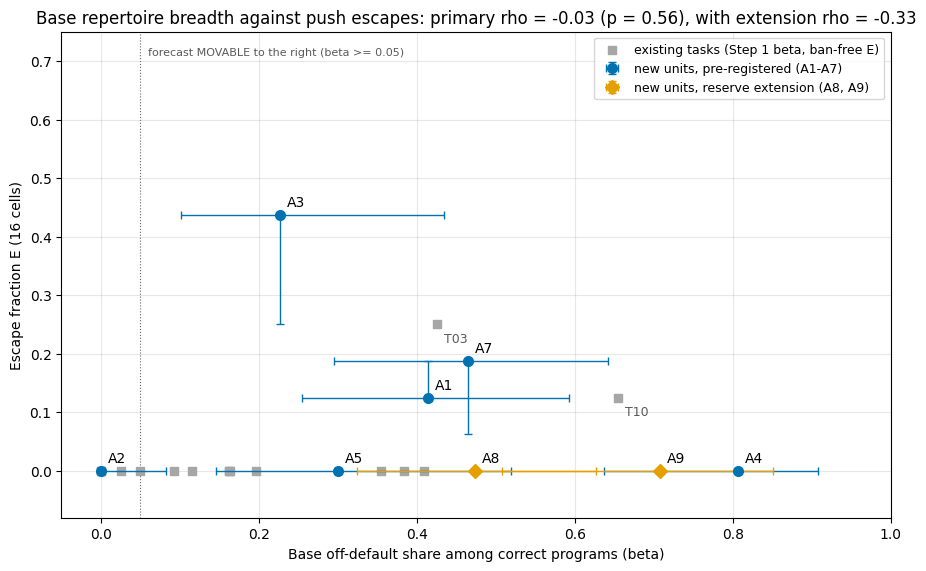

In [22]:
def e_boot(u: str, d: str, cat: list[str], n_boot: int = E_BOOT, seed: int = 11) -> tuple[float, float]:  # figures5.py
    """90% interval of E_u under resampling of rows within the twin and within each escape cell (stage-1 and top-up
    slots resampled separately) -- the measurement bootstrap of the frozen analysis, per unit."""
    rows = labels(u)
    tw = rows_of(rows, "TWIN", "instruct")
    esc = rows_of(rows, prefix="ESC_", model="instruct")
    cells = [[r for r in esc if int(r["direction_seed"]) == s and abs(float(r["alpha"]) - a) < 1e-9]
             for s in ESC_SEEDS for a in ALPHAS]
    rng = np.random.default_rng(seed)
    out = []
    for _ in range(n_boot):
        twb = [tw[i] for i in rng.integers(0, len(tw), len(tw))]
        ts = twin_stats(twb, set(cat), d)
        conf = 0
        for c in cells:
            f = [r for r in c if int(r["slot"]) in (0, 1)]
            t = [r for r in c if int(r["slot"]) in (2, 3, 4, 5)]
            fb = [f[i] for i in rng.integers(0, len(f), len(f))] if f else []
            tb = [t[i] for i in rng.integers(0, len(t), len(t))] if t else []
            conf += cell_decision(fb + tb, ts, set(cat), d)["confirmed"]
        out.append(conf / len(cells))
    return float(np.percentile(out, 5)), float(np.percentile(out, 95))


fig, ax = plt.subplots(figsize=(9, 5.6), layout="constrained")
ex_rows = [r for r in hs.get("rows", []) if r["kind"] == "existing"]
ax.scatter([r["beta"] for r in ex_rows], [r["E"] for r in ex_rows], s=28, marker="s", color="0.65", zorder=2,
           label="existing tasks (Step 1 beta, ban-free E)")
for kind, marker, color, lab in (("primary", "o", "#0072B2", "new units, pre-registered (A1-A7)"),
                                 ("ext", "D", "#E69F00", "new units, reserve extension (A8, A9)")):
    us = [u for u in UNITS if (u in NEW_UNITS) == (kind == "primary")]
    x = np.array([P[u]["beta"] for u in us])
    y = np.array([summ[u]["outcome"]["E"] for u in us])
    ci = [e_boot(u, P[u]["default"], P[u]["catalogue"]) for u in us]
    xe = np.array([[x[i] - P[u]["beta_ci"][0], P[u]["beta_ci"][1] - x[i]] for i, u in enumerate(us)]).T
    ye = np.array([[max(0.0, y[i] - ci[i][0]), max(0.0, ci[i][1] - y[i])] for i in range(len(us))]).T
    ax.errorbar(x, y, xerr=xe, yerr=ye, fmt=marker, ms=7, capsize=3, lw=1, color=color, zorder=3, label=lab)
    for u, xi, yi in zip(us, x, y):
        ax.annotate(u, (xi, yi), textcoords="offset points", xytext=(5, 6), fontsize=10)
for r in ex_rows:
    if r["E"] > 0:
        ax.annotate(r["unit"], (r["beta"], r["E"]), textcoords="offset points", xytext=(5, -13), fontsize=9,
                    color="0.35")
ax.axvline(BETA_MOVABLE, color="0.4", lw=0.8, ls=":", zorder=1)
ax.text(BETA_MOVABLE + 0.01, 0.71, "forecast MOVABLE to the right (beta >= 0.05)", fontsize=8, color="0.35")
ax.set(xlabel="Base off-default share among correct programs (beta)", ylabel="Escape fraction E (16 cells)",
       xlim=(-0.05, 1.0), ylim=(-0.08, 0.75),
       title=f"Base repertoire breadth against push escapes: primary rho = {a1p['rho_beta_E']:.2f} "
             f"(p = {a1p['perm_p_one_sided']:.2f}), with extension rho = {a1x['rho_beta_E']:.2f}")
ax.legend(loc="upper right", fontsize=9)
ax.grid(alpha=0.3)
plt.show()

### Figure 2: per-direction escape outcomes

This is the artifact's `fig2`. There is one row per unit, plus the six existing tasks that were movable in iteration 4 or on the screen, and one column per direction (seed − 95100) × dose. The top panel shows the stage-1 off-default excess over the twin. The bottom panel shows each cell's outcome under the two-stage rule. Escapes are sparse and direction-specific. For A1 and A7 they appear only at α = 2. T05, T06, T1 and T2 were called movable by the frozen screen, which used iteration 4's ban unit; none of them escape here.

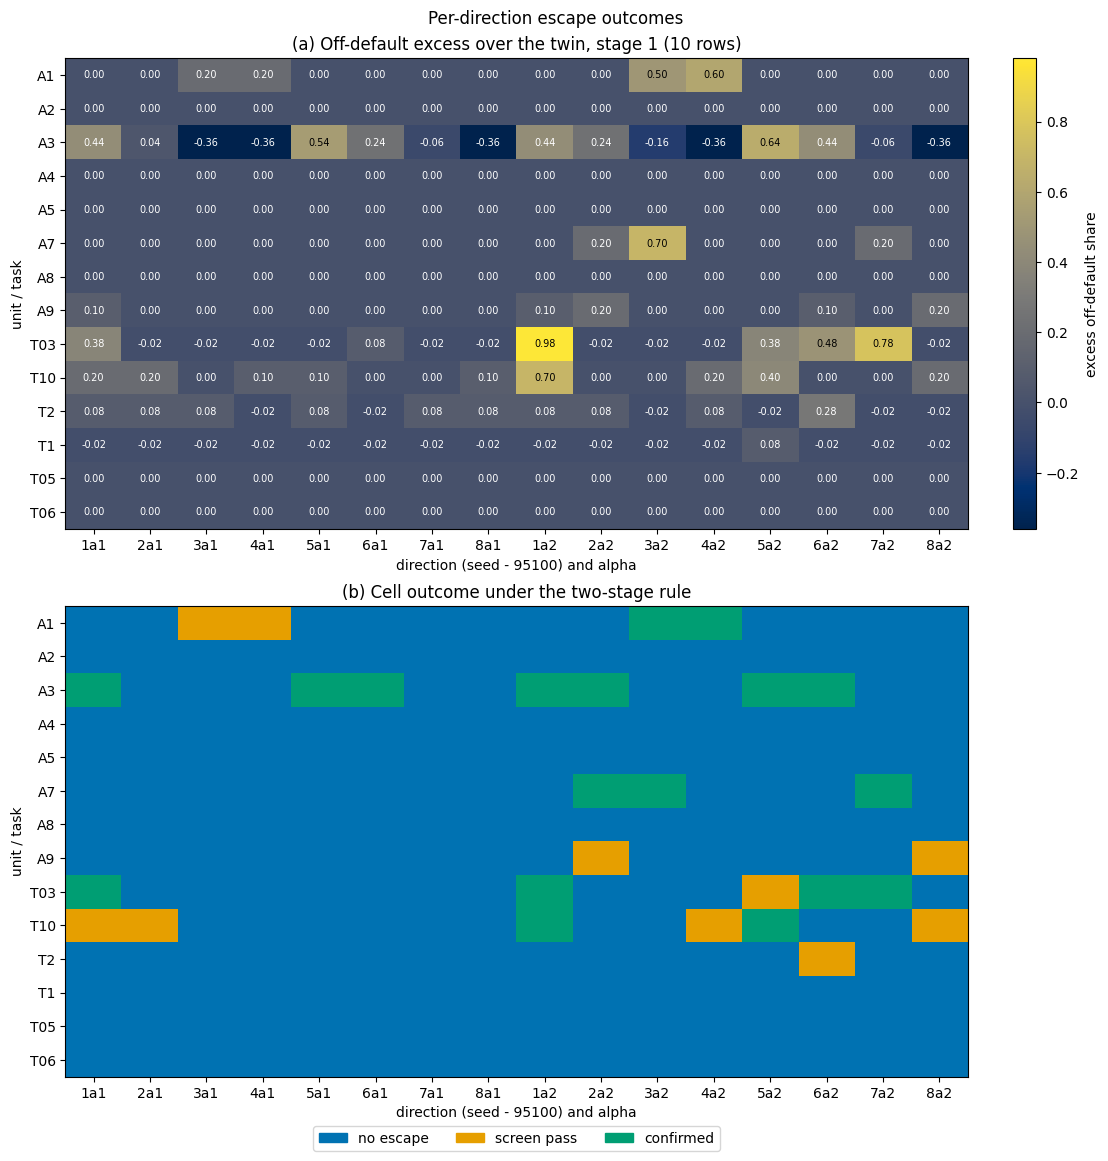

In [23]:
cols = [f"{s - 95100}a{int(a)}" for a in ALPHAS for s in ESC_SEEDS]
order = [u for u in UNITS if P[u].get("status") == "OK"] + ["T03", "T10", "T2", "T1", "T05", "T06"]
mat, outcome = [], []
for t in order:  # figures5.fig2
    cells = summ[t]["escape_cells"] if t in summ else xa[t]["cells"]
    by = {(c["seed"], c["alpha"]): c for c in cells}
    mat.append([by[(s, a)]["excess10"] if by[(s, a)]["excess10"] is not None else 0.0
                for a in ALPHAS for s in ESC_SEEDS])
    outcome.append([2 if by[(s, a)]["confirmed"] else 1 if by[(s, a)]["screen_pass"] else 0
                    for a in ALPHAS for s in ESC_SEEDS])
mat, outcome = np.array(mat), np.array(outcome)

fig, axes = plt.subplots(2, 1, figsize=(11, 11.5), layout="constrained")
im = axes[0].imshow(mat, cmap="cividis", aspect="auto")
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        axes[0].text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=7,
                     color="w" if mat[i, j] < 0.45 else "k")
fig.colorbar(im, ax=axes[0], label="excess off-default share")
axes[0].set_title("(a) Off-default excess over the twin, stage 1 (10 rows)")
cmap3 = ListedColormap(["#0072B2", "#E69F00", "#009E73"])
axes[1].imshow(outcome, cmap=cmap3, vmin=0, vmax=2, aspect="auto")
axes[1].set_title("(b) Cell outcome under the two-stage rule")
axes[1].legend(handles=[Patch(color=c, label=l) for c, l in zip(cmap3.colors, ["no escape", "screen pass", "confirmed"])],
               loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3)
for ax in axes:
    ax.set_xticks(range(len(cols)), cols)
    ax.set_yticks(range(len(order)), order)
    ax.set_xlabel("direction (seed - 95100) and alpha")
    ax.set_ylabel("unit / task")
fig.suptitle("Per-direction escape outcomes")
plt.show()

### Figure 3 and the A2 events: where the pushes land

On each of the three A2 events (A1, A3, A7) the landing equals the base runner-up r_u. The table gives each forecast's mean log probability of the realised landing labels (higher is better). The figure is the artifact's `fig3`: program compositions per unit for the twin, the base model's correct programs, plan noise at α = 2 and the confirmed escape cells. In the confirmed cells, the red runner-up share takes over from the blue default.

,forecast r_u,landing L_u,hit,n realised,base,association (committed),"association (corrected, POST HOC)",proximity
unit,,,,,,,,
A1,boyer_moore_vote,boyer_moore_vote,True,35,-0.063,-1.812,-0.274,-1.636
A3,two_pointers,two_pointers,True,160,-0.054,-1.119,-0.143,-1.122
A7,brute_force,brute_force,True,33,-0.625,-1.119,-2.868,-0.945


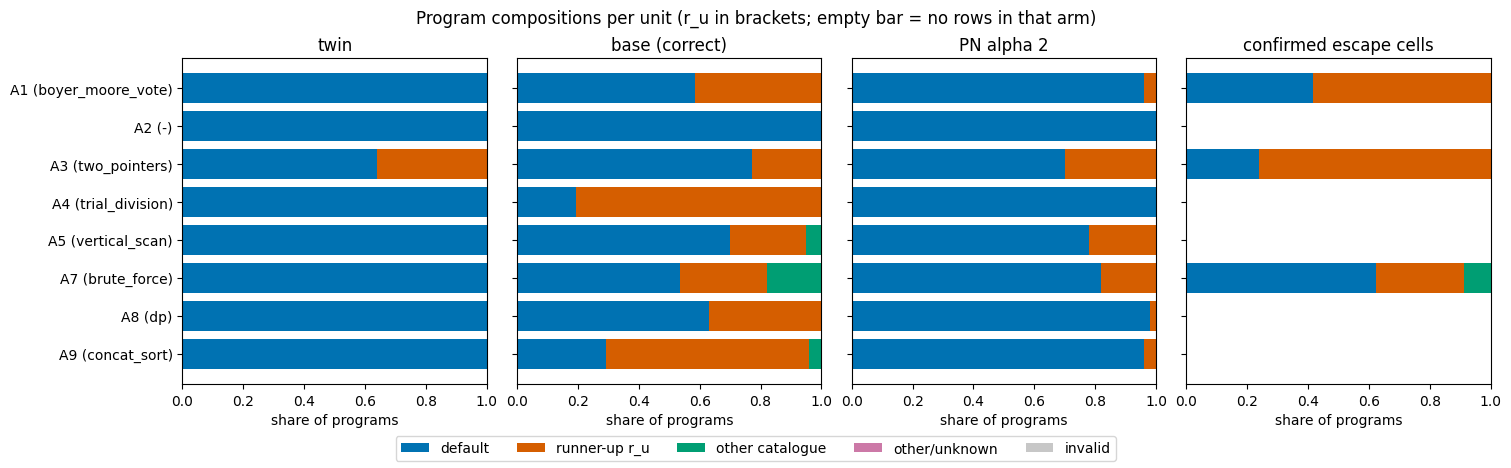

In [24]:
display(pd.DataFrame([{"unit": e["unit"], "forecast r_u": e["r"], "landing L_u": e["L"], "hit": e["hit"],
                       "n realised": e["n_realised"], "base": e["log_scores"]["base"],
                       "association (committed)": e["log_scores"]["assoc"],
                       "association (corrected, POST HOC)": c["log_scores"]["assoc"],
                       "proximity": e["log_scores"]["prox"]}
                      for e, c in zip(a2p["events"], a2c["events"])]).set_index("unit").round(3))


def comp_rows(u: str, P: dict, summ: dict) -> dict:  # figures5.py
    p = P[u]
    d, r, cat = p["default"], p.get("r"), set(p["catalogue"])
    rows = labels(u)

    def bucket(lab: str) -> str:
        if lab == d:
            return "default"
        if r and lab == r:
            return "runner-up r_u"
        if lab in cat:
            return "other catalogue"
        if lab in ("invalid", "disputed"):
            return "invalid"
        return "other/unknown"
    out = {}
    conf = [(c["seed"], c["alpha"]) for c in summ[u]["escape_cells"] if c["confirmed"]]
    for arm, sel in (("twin", rows_of(rows, "TWIN", "instruct")),
                     ("base (correct)", [x for x in rows_of(rows, "BASE", "base") if x.get("passed")]),
                     ("PN alpha 2", rows_of(rows, "PN_a2.0", "instruct")),
                     ("confirmed escape cells", [x for x in rows_of(rows, prefix="ESC_", model="instruct")
                                                 if (int(x["direction_seed"]), float(x["alpha"])) in conf])):
        out[arm] = Counter(bucket(x["label"]) for x in sel)
    return out


keys = ["default", "runner-up r_u", "other catalogue", "other/unknown", "invalid"]
colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "0.78"]
comps = {u: comp_rows(u, P, summ) for u in UNITS}
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), sharey=True, layout="constrained")
for ax, arm in zip(axes, ("twin", "base (correct)", "PN alpha 2", "confirmed escape cells")):
    left = np.zeros(len(UNITS))
    for k, col in zip(keys, colors):
        vals = np.array([comps[u][arm].get(k, 0) / max(1, sum(comps[u][arm].values())) for u in UNITS])
        ax.barh(range(len(UNITS)), vals, left=left, color=col, label=k)
        left += vals
    ax.set_title(arm)
    ax.set_xlim(0, 1)
    ax.set_xlabel("share of programs")
axes[0].set_yticks(range(len(UNITS)), [f"{u} ({P[u]['r'] or '-'})" for u in UNITS])
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), loc="outside lower center", ncol=5)
fig.suptitle("Program compositions per unit (r_u in brackets; empty bar = no rows in that arm)")
plt.show()

### Figures 4 and 5: the rival predictors, and Extra arm A

The scatter panels are the artifact's `fig5`: every pre-registered predictor against E over the eight new units. Within the primary set, two rivals track E far better than β does:

* the **runtime merit**: units with an alternative at least twice as fast as the default move;
* the **twin's modal share**.

The right panel is the artifact's `fig4`. It compares E for the 15 existing tasks under iteration 4's ban unit with E under this run's ban-free unit. Only T03 and T10, the positive controls, still escape.

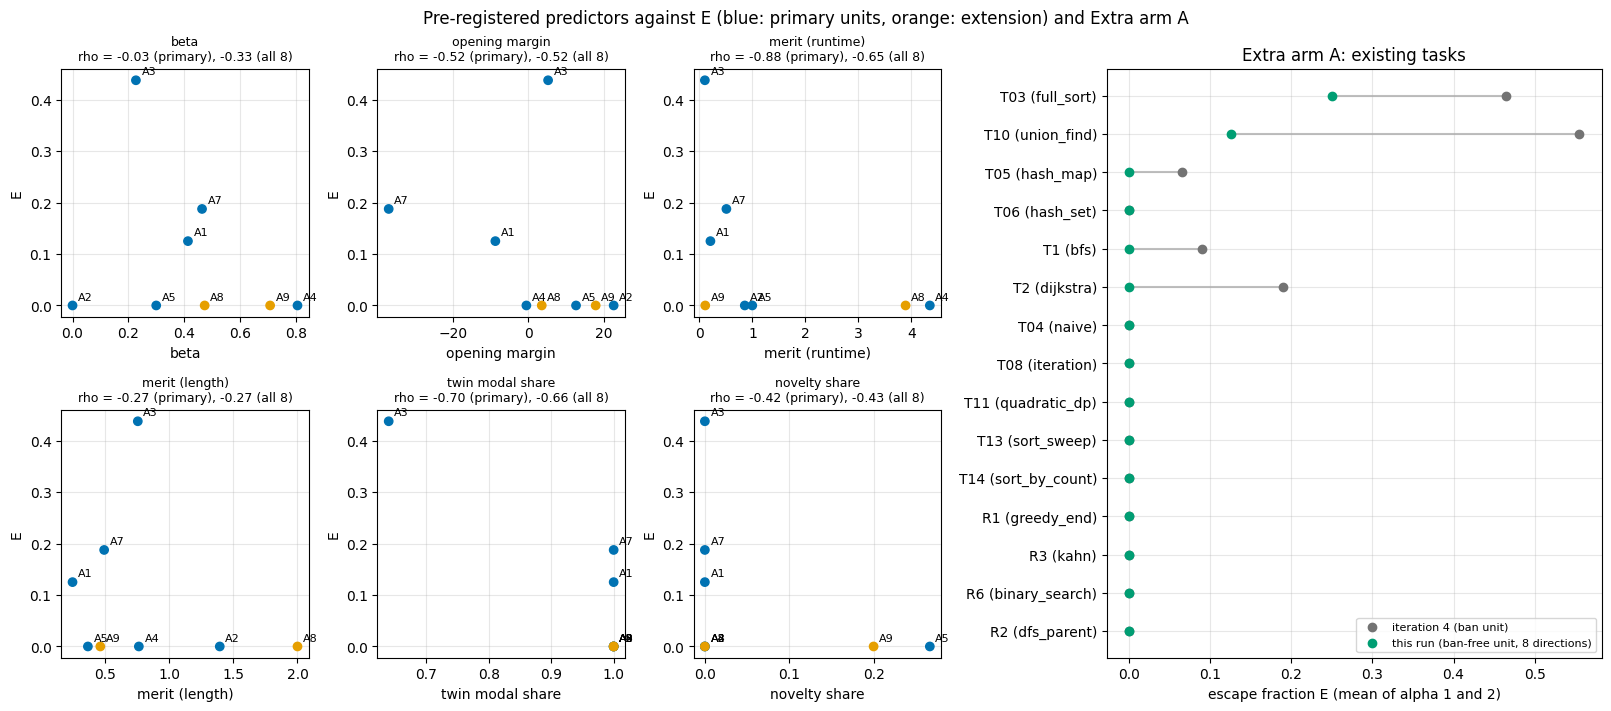

,default,E,E1,E2,landing,screen called movable,verdict changed
task,,,,,,,
T03,full_sort,0.250,0.125,0.375,size_k_heap,True,False
T10,union_find,0.125,0.000,0.250,dfs,True,False
T05,hash_map,0.000,0.000,0.000,-,True,True
T06,hash_set,0.000,0.000,0.000,-,True,True
T1,bfs,0.000,0.000,0.000,-,True,True
T2,dijkstra,0.000,0.000,0.000,-,True,True
T04,naive,0.000,0.000,0.000,-,False,False
T08,iteration,0.000,0.000,0.000,-,False,False
T11,quadratic_dp,0.000,0.000,0.000,-,False,False


In [25]:
preds_ = [("beta", lambda p: p["beta"]),  # figures5.fig5
          ("opening margin", lambda p: p["rivals"].get("opening_margin")),
          ("merit (runtime)", lambda p: p["rivals"].get("merit_runtime_min")),
          ("merit (length)", lambda p: p["rivals"].get("merit_length_min")),
          ("twin modal share", lambda p: p["rivals"].get("twin_modal_share")),
          ("novelty share", lambda p: p["rivals"].get("novelty_share"))]
units_ok = [u for u in UNITS if P[u].get("status") == "OK"]
E_ok = [summ[u]["outcome"]["E"] for u in units_ok]
fig = plt.figure(figsize=(16, 7), layout="constrained")
gs = fig.add_gridspec(2, 5)
for i, (name, get) in enumerate(preds_):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    xs = [get(P[u]) for u in units_ok]
    ax.scatter(xs, E_ok, c=["#0072B2" if u in NEW_UNITS else "#E69F00" for u in units_ok], zorder=3)
    for u, x_, e_ in zip(units_ok, xs, E_ok):
        ax.annotate(u, (x_, e_), textcoords="offset points", xytext=(4, 4), fontsize=8)
    prim = [j for j, u in enumerate(units_ok) if u in NEW_UNITS]
    ax.set_title(f"{name}\nrho = {spearman([xs[j] for j in prim], [E_ok[j] for j in prim]):.2f} (primary), "
                 f"{spearman(xs, E_ok):.2f} (all 8)", fontsize=9)
    ax.set(xlabel=name, ylabel="E")
    ax.grid(alpha=0.3)
tasks = [t for t in EXISTING if t in xa]  # figures5.fig4
it4 = [float(np.mean(xa[t]["iter4_E1_E2"])) for t in tasks]
now = [float(xa[t]["E"] or 0.0) for t in tasks]
ax = fig.add_subplot(gs[:, 3:])
yy = np.arange(len(tasks))
ax.hlines(yy, it4, now, color="0.75", zorder=1)
ax.scatter(it4, yy, color="0.45", zorder=2, label="iteration 4 (ban unit)")
ax.scatter(now, yy, color="#009E73", zorder=3, label="this run (ban-free unit, 8 directions)")
ax.set_yticks(yy, [f"{t} ({xa[t]['default']})" for t in tasks])
ax.invert_yaxis()
ax.set(xlabel="escape fraction E (mean of alpha 1 and 2)", title="Extra arm A: existing tasks")
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.3)
fig.suptitle("Pre-registered predictors against E (blue: primary units, orange: extension) and Extra arm A")
plt.show()

display(pd.DataFrame([{"task": t, "default": v["default"], "E": v["E"], "E1": v["E1"], "E2": v["E2"],
                       "landing": v["landing"] or "-", "screen called movable": v["screen_movable"],
                       "verdict changed": v["verdict_change"]} for t, v in xa.items()]).set_index("task"))

## Takeaways

* **A1 (whether a task moves) is not supported in this panel.** On the six pre-registered units, ρ(β, E) ≈ 0 (−0.03, exact p = 0.56). The one base-collapsed unit (A2, β = 0) is immovable, as predicted. But base-diverse units are often immovable too: A4 (count primes, β = 0.81), A5 and the reserves A8 and A9 never escape. With the extension included, ρ turns negative (−0.33). Two trivial rivals track E better than β:
  * the runtime ratio of the fastest alternative (ρ = −0.88);
  * the twin's modal share (ρ = −0.70).
* **A2 (where a pushed task lands) is supported.** On all three movable units (A1, A3, A7), the base model's runner-up r_u is exactly the landing L_u (Poisson-binomial p = 0.019). On log score, the base composition beats AST proximity. It also beats the association prompt, including after the post hoc mapping fix. No pushed program lands outside the base model's repertoire.
* **What this says about "creative" solutions.** In this panel, a push in activation space never produced a new algorithm. When it moved the model at all, the model landed on the base model's runner-up: an algorithm already in the pre-trained repertoire. Whether a task moves tracked two other things better than repertoire breadth: whether a clearly faster alternative exists (runtime merit), and how locked-in the instruct model's default is.
* **Caveats.** The panel covers one model family, memorised LeetCode problems, n = 6 primary units and three A2 events. Power is about 0.46 even for a true ρ = 0.6, so the A1 null is weak evidence on its own; the rival results and the A4/A8/A9 counter-examples say more. The 'half + screen' ρ = 0.54 is descriptive only, and 13 immovable existing tasks drive it.

### Scaling the demo
The config cell holds the original counts: `N_BOOT = 2000`, `N_BOOT_RIVAL = 10000`, `HILL_N_SUB = 1000`, `N_PERM_RANDOM = 10000`, `E_BOOT = 500`. In the Colab-like test environment (2 CPU cores) the whole notebook ran in about 53 s, including the installs; the `final` stage took about 36 s. All 30 headline numbers matched the artifact exactly. At 10% of those counts the run took 22 s. Every point estimate is exact at any config; only the bootstrap and random-permutation rows then approximate.

### Checks of the artifact that are not re-run here
These numbers are quoted from the artifact's `results/` and `audit/`:

* **Novelty audit (LLM judges).** Among 6,854 correct programs, 2 are labelled 'other': 1 catalogue variant and 1 degenerate program. None is a novel algorithm.
* **Engine check against the FP8 screen.** The twins reproduce the screen rows: per-slot label agreement is 1.00 for T03 and 0.98 for T2. The pushed cells are precision-sensitive (0.74 and 0.86).
* **Labellers and external references.** Every gated labeller agrees on 100% of its references. 8 of 9 external TheAlgorithms implementations pass the frozen hidden tests.
* **Independent re-derivations** (`audit/rederive.py`, `audit/rederive2.py`): 0 mismatches. Shuffling β across units gives a mean ρ of 0.00, so the placebos fail as they must.